# Pharmacy closures and access in Philadelphia, 2023–2025
**Emmanuel Amissah Sampson · University of Pennsylvania**

This is the main historical-evidence and before-and-after research record. The historical ledger covers **selected 2023–2025 episodes**. The route comparison uses **24 company-reported 2025 transfers**, with final pharmacy days from June 4 to August 8. It is a focused part of the wider investigation, not a complete three-year travel panel.

The executed results measure access to former and designated receiving destinations. Actual journeys, mode shifts and causal emissions effects are not observed. The 2022–2025 mobility panel remains to be acquired.

In [1]:
from pathlib import Path
import sys, json, hashlib
ROOT = Path.cwd()
if not (ROOT / 'config.json').exists(): ROOT = ROOT.parent
assert (ROOT / 'config.json').exists()
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display, Image
OUT = ROOT / 'outputs/public'
pd.set_option('display.max_columns', 12)


## 1. Periods and evidence
The ACS estimates cover 2018–2022. The street graph represents mapped data through January 1, 2025, held fixed for both destinations. Company dates, court-filing dates, scheduled store closures and actual pharmacy days are different fields.

The source ledgers preserve row/page references and address disagreements. The original company archive can be retrieved with `python -m src.transfers --download`. The independent insurer directory can be checked with `python -m src.corroboration --download` (requires Poppler's `pdftotext`). Public factual derivatives are included even if the source PDFs are not redistributed.

,selected_locations
evidence_year,
2023,13
2024,4
2025,24


,address,evidence_year,reported_date,date_meaning
0,5612 N. FIFTH STREET,2023,NaN,court motion listing; operating date not estab...
1,4011 COTTMAN AVENUE,2023,NaN,court motion listing; operating date not estab...
2,11750 BUSTLETON AVENUE,2023,NaN,court motion listing; operating date not estab...
3,1315 EAST WASHINGTON LANE,2023,NaN,court motion listing; operating date not estab...
4,2801 W. DAUPHIN STREET,2023,NaN,court motion listing; operating date not estab...
5,8235 STENTON AVENUE,2023,NaN,court motion listing; operating date not estab...
6,7941 OXFORD AVENUE,2023,NaN,court motion listing; operating date not estab...
7,136 NORTH 63RD STREET,2023,NaN,court motion listing; operating date not estab...
8,5440 LANSDOWNE AVENUE,2023,NaN,court motion listing; operating date not estab...
9,2401 EAST VENANGO STREET,2023,NaN,court motion listing; operating date not estab...


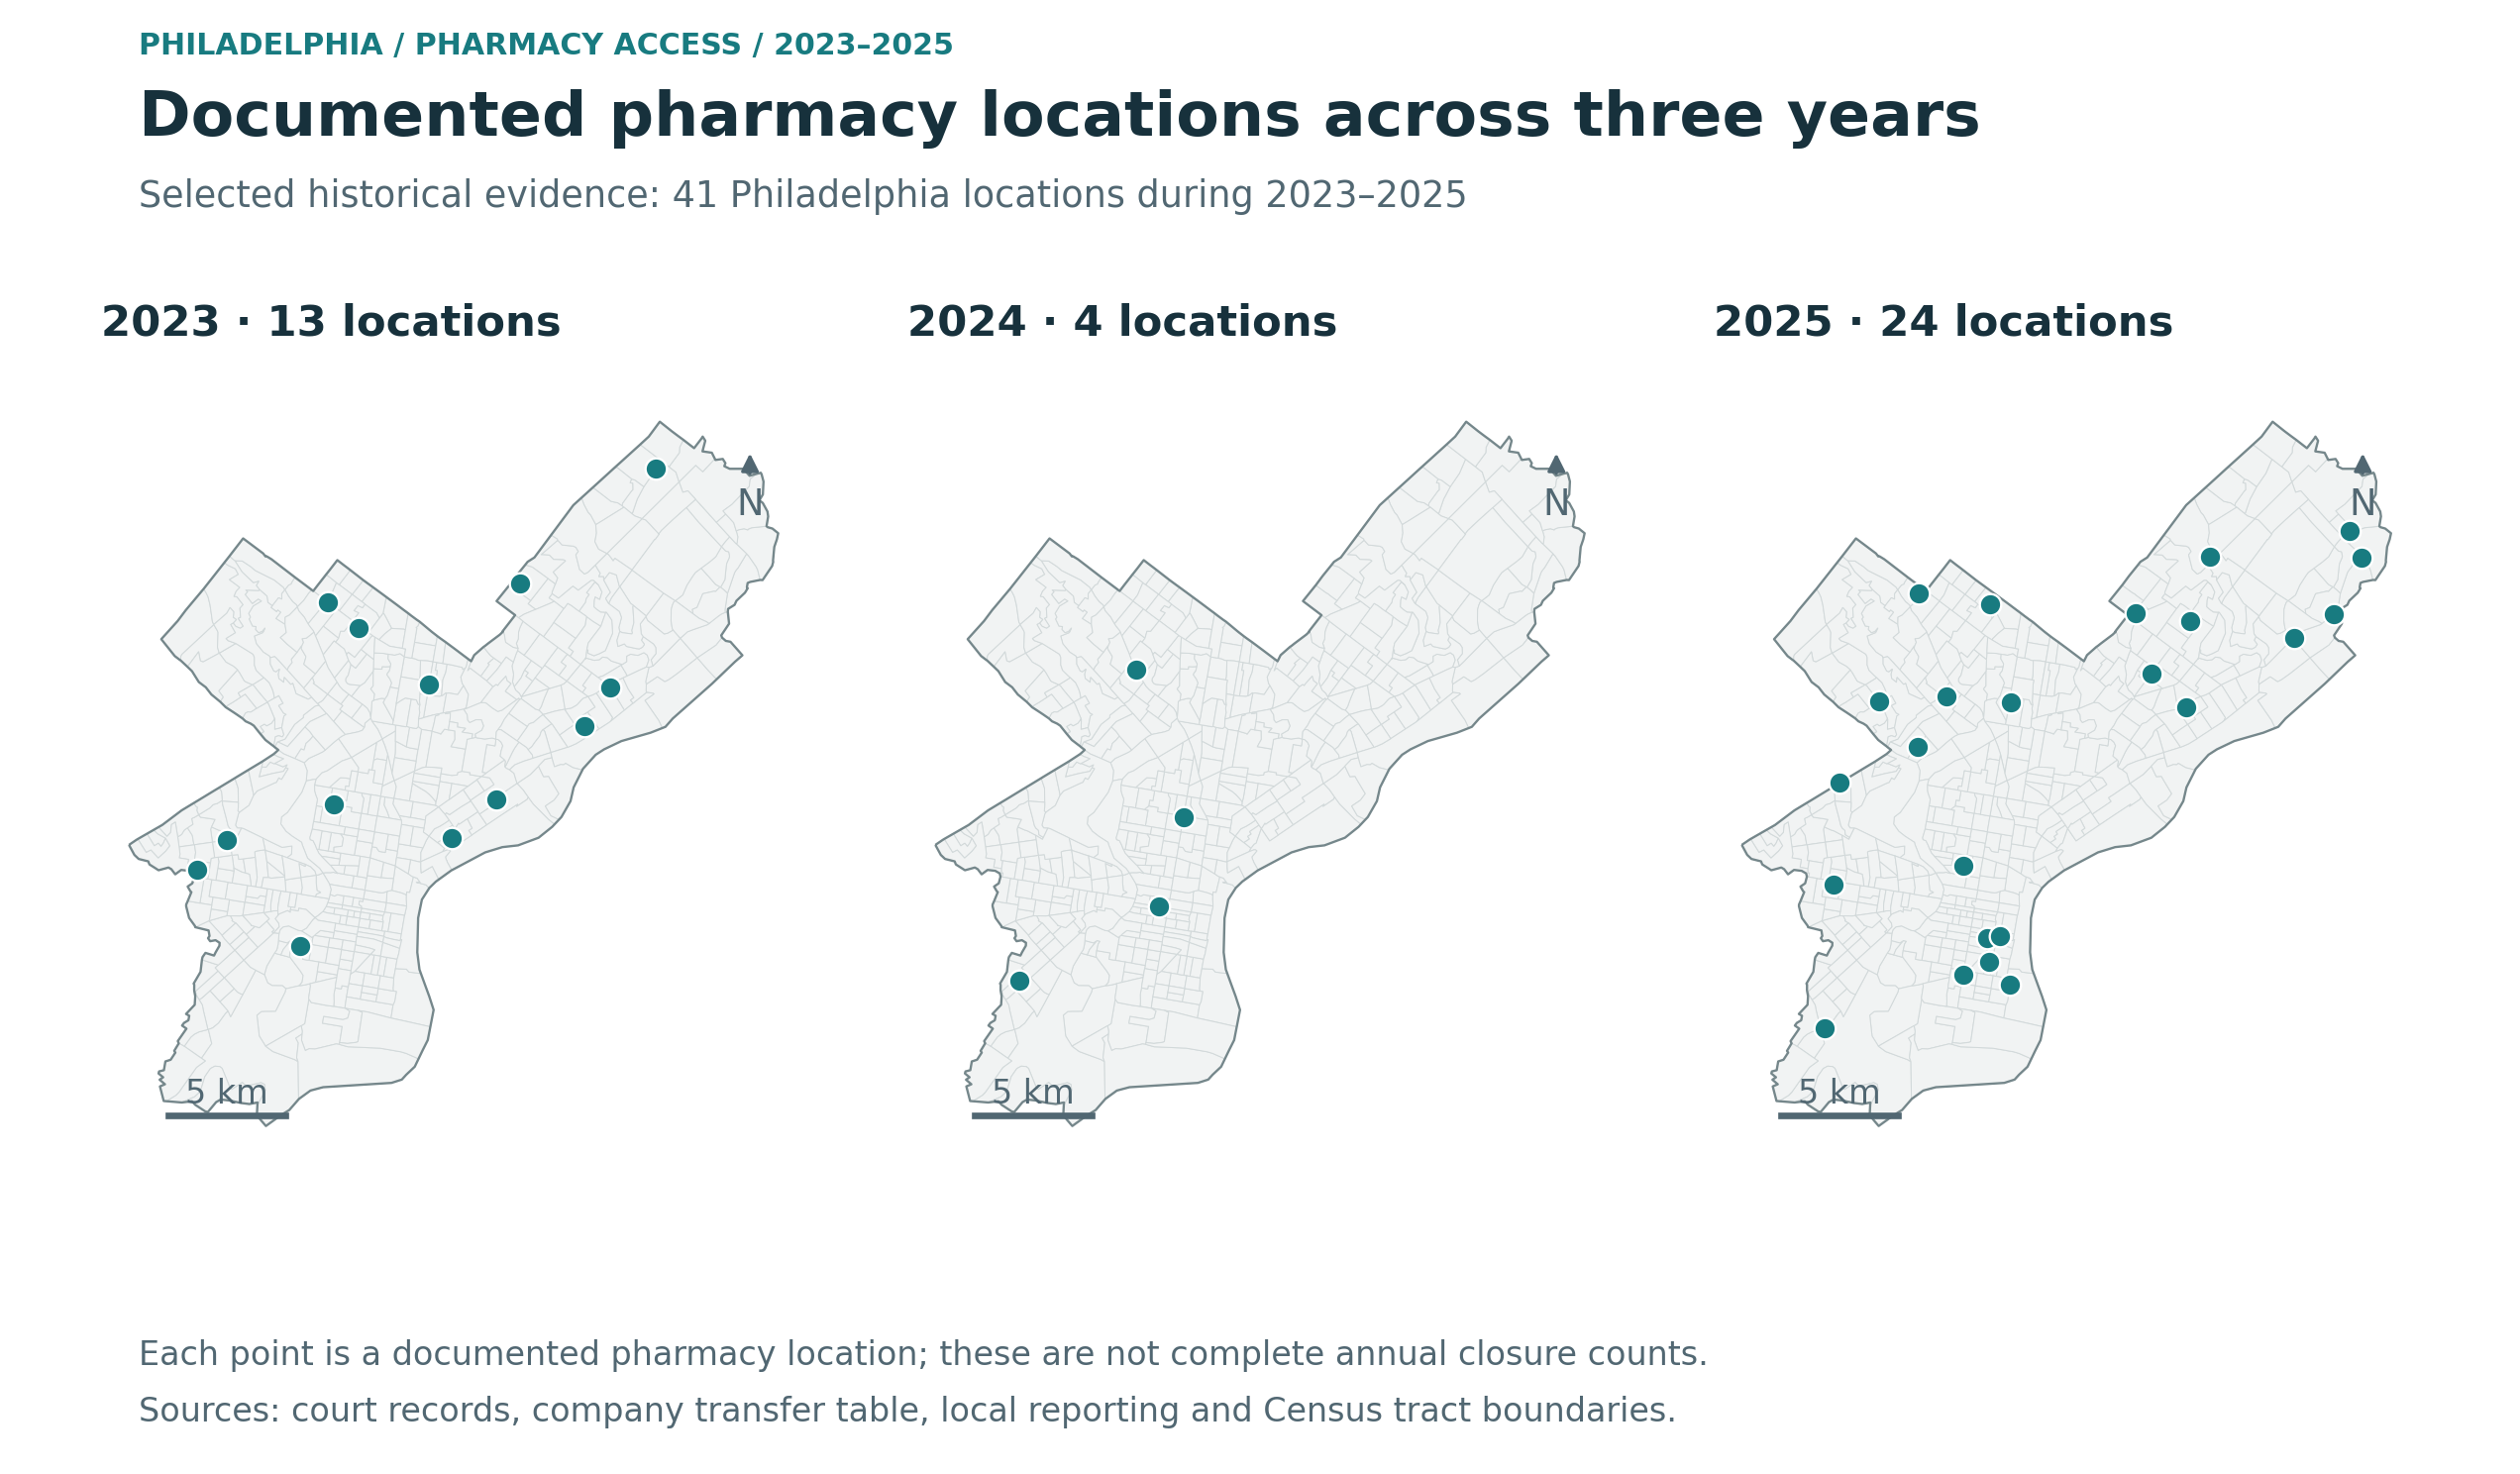

In [2]:
history = pd.read_csv(ROOT / 'data/processed/historical_evidence_2023_2025.csv', dtype={'store_number': str})
assert len(history) == 41
assert not history.normalized_address.duplicated().any()
display(history.groupby('evidence_year').size().rename('selected_locations').to_frame())
display(history[['address','evidence_year','reported_date','date_meaning']].head(17))
display(Image(filename=str(OUT / 'closure_evidence_map.png')))


## 2. Corroboration is specific to a claim
The May 5, 2025 insurer directory corroborates listed store identity, not an exact closing day. Court notices show selection for closure. Reporting that copies the company table is not an independent check of that table. No exact-address closure day is marked independently confirmed in this audit.

The Academy Road address differs between sources. It is excluded from the primary route sample, with an inclusion sensitivity. Same-site transfer at Chestnut Street is retained but does not establish uninterrupted service.

In [3]:
pairs = pd.read_csv(ROOT / 'data/processed/philadelphia_transfer_pairs_2025.csv', dtype={'store_number': str})
audit = pd.read_csv(ROOT / 'data/processed/transfer_corroboration_2025.csv', dtype={'store_number': str})
assert len(pairs) == 24 and pairs.store_number.is_unique
assert audit.in_preclosure_insurer_directory.all()
assert not audit.independent_exact_address_date_confirmed.any()
assert audit.loc[audit.store_number.eq('1956'), 'primary_routing_eligible'].eq(False).all()
display(audit[['store_number','old_address','pharmacy_last_open_date','directory_address','in_selected_2025_court_notice']])
display(pd.Series(json.loads((OUT / 'transfer_corroboration_summary.json').read_text())))


,store_number,old_address,pharmacy_last_open_date,directory_address,in_selected_2025_court_notice
0,11136,1334 WINDRIM AVENUE,2025-06-04,1334 WINDRIM AVENUE,False
1,1941,7401 OGONTZ AVENUE,2025-06-25,7401 OGONTZ AVENUE,True
2,7834,9200 FRANKFORD AVENUE,2025-06-26,9200 FRANKFORD AVENUE,True
3,872,164 WEST CHELTEN AVENUE,2025-07-01,164 WEST CHELTEN AVENUE,False
4,1956,12311 ACADEMY ROAD,2025-07-01,12353 ACADEMY ROAD,True
5,3637,6363 FRANKFORD AVENUE,2025-07-02,6363 FRANKFORD AVENUE,True
6,1936,2017-2023 SOUTH BROAD ST.,2025-07-08,2017 2023 SOUTH BROAD STREET,True
7,11139,6515 CASTOR AVENUE,2025-07-13,6515 CASTOR AVENUE,False
8,4611,5040 CITY LINE AVENUE,2025-07-16,5040 CITY LINE AVENUE,False
9,1766,10 SNYDER AVENUE,2025-07-17,10 SNYDER AVENUE SNYDER PLAZA,False


directory_as_of                                                                        2025-05-05
directory_philadelphia_rite_aids                                                               34
transfer_sites                                                                                 24
transfer_sites_with_directory_identity_match                                                   24
transfer_sites_in_selected_court_notice                                                         5
exact_dates_independently_confirmed                                                             0
neighborhood_level_date_consistency                                                             1
address_conflicts                                                                               1
interpretation                                  Corroborated listed site identities and select...
dtype: object

## 3. Network provenance
Tract centers are calculated after projecting boundaries to NAD83 / UTM zone 18N (EPSG:26918), in meters; planar catchments and maps use the same projection. Stored geographic coordinates use WGS84 (EPSG:4326). Network routes sum street-edge lengths and great-circle node-connector distances in meters, never planar distances in degrees.

The release package contains cached graph files; a Git clone must first run `python scripts/download_historical_networks.py`. The downloader retrieves the 296 MB historical Pennsylvania OSM extract and constructs walk/drive graphs. It can require several GB of working memory. The manifest records the original extract and graph hashes.

Routes minimize distance and preserve driving direction. Short straight node connectors are recorded separately. Turn restrictions, traffic delays, complete node barriers and conditional permissions are not modeled. These are mapped routes, not observed trajectories.

In [4]:
network = json.loads((ROOT / 'data/historical_network_manifest.json').read_text())
for item in network['files']:
    path = ROOT / item['file']
    assert path.exists(), 'Run scripts/download_historical_networks.py or use the cached release package'
    assert hashlib.sha256(path.read_bytes()).hexdigest() == item['sha256']
display(pd.DataFrame(network['files'])[['mode','nodes','edges','bytes']])
print('Fixed mapped network:', network['snapshot_utc'])


,mode,nodes,edges,bytes
0,walk,524415,1228152,369745868
1,drive,367266,731235,234613901


Fixed mapped network: 2025-01-01T21:21:00Z


## 4. Calculate before and after access
Assign each populated tract center to the nearest of the 24 former study pharmacies, then retain origins within 800 m for the primary sample. This is a geographic catchment rule, not an observed customer assignment. Both outcomes use the same origins and population weights. The after destination is the documented recipient, not the nearest pharmacy of any brand.

The common sample requires reachable outward and return routes, maximum endpoint-to-node distance of 200 m, and no unresolved former-address conflict. Walking minutes assume 4.8 km/h. Driving round trips are routed in both directions rather than doubling a one-way distance.

In [5]:
from src.transfer_access import build
origins, summary = build()
main = origins.loc[origins.main_included].copy()
assert len(main) == summary['tracts']
assert np.isfinite(main[['walk_before_km','walk_after_km','drive_before_roundtrip_km','drive_after_roundtrip_km']]).all().all()
assert not main.unresolved_address_conflict.any()
assert main.max_snap_m.le(200).all()
same_site = main.loc[main.same_address_transfer]
assert np.allclose(same_site.walk_delta_km, 0)
assert np.allclose(same_site.drive_delta_roundtrip_km, 0)
print('Origins are modeled residential-area proxies, not sampled travelers.')


{
  "tracts": 62,
  "population_context": 262710,
  "represented_transfer_pairs": 22,
  "weighted_walk_before_km": 0.7163861409985092,
  "median_walk_before_km": 0.7486725884339358,
  "weighted_walk_after_km": 1.2810703755888897,
  "median_walk_after_km": 1.0766668602566427,
  "weighted_walk_delta_km": 0.5646842345903809,
  "median_walk_delta_km": 0.4850718317254706,
  "weighted_walk_before_minutes": 8.95482676248137,
  "median_walk_before_minutes": 9.358407355424198,
  "weighted_walk_after_minutes": 16.01337969486113,
  "median_walk_after_minutes": 13.458335753208033,
  "weighted_walk_delta_minutes": 7.058552932379761,
  "median_walk_delta_minutes": 6.063397896568382,
  "weighted_drive_before_roundtrip_km": 1.6062632356391902,
  "median_drive_before_roundtrip_km": 1.6572407681865773,
  "weighted_drive_after_roundtrip_km": 2.7504362398075424,
  "median_drive_after_roundtrip_km": 2.380386532933769,
  "weighted_drive_delta_roundtrip_km": 1.1441730041683522,
  "median_drive_delta_roundtri

,measure,before,after,difference
0,One-way walking minutes,8.95,16.01,7.06
1,Driving round-trip km,1.61,2.75,1.14


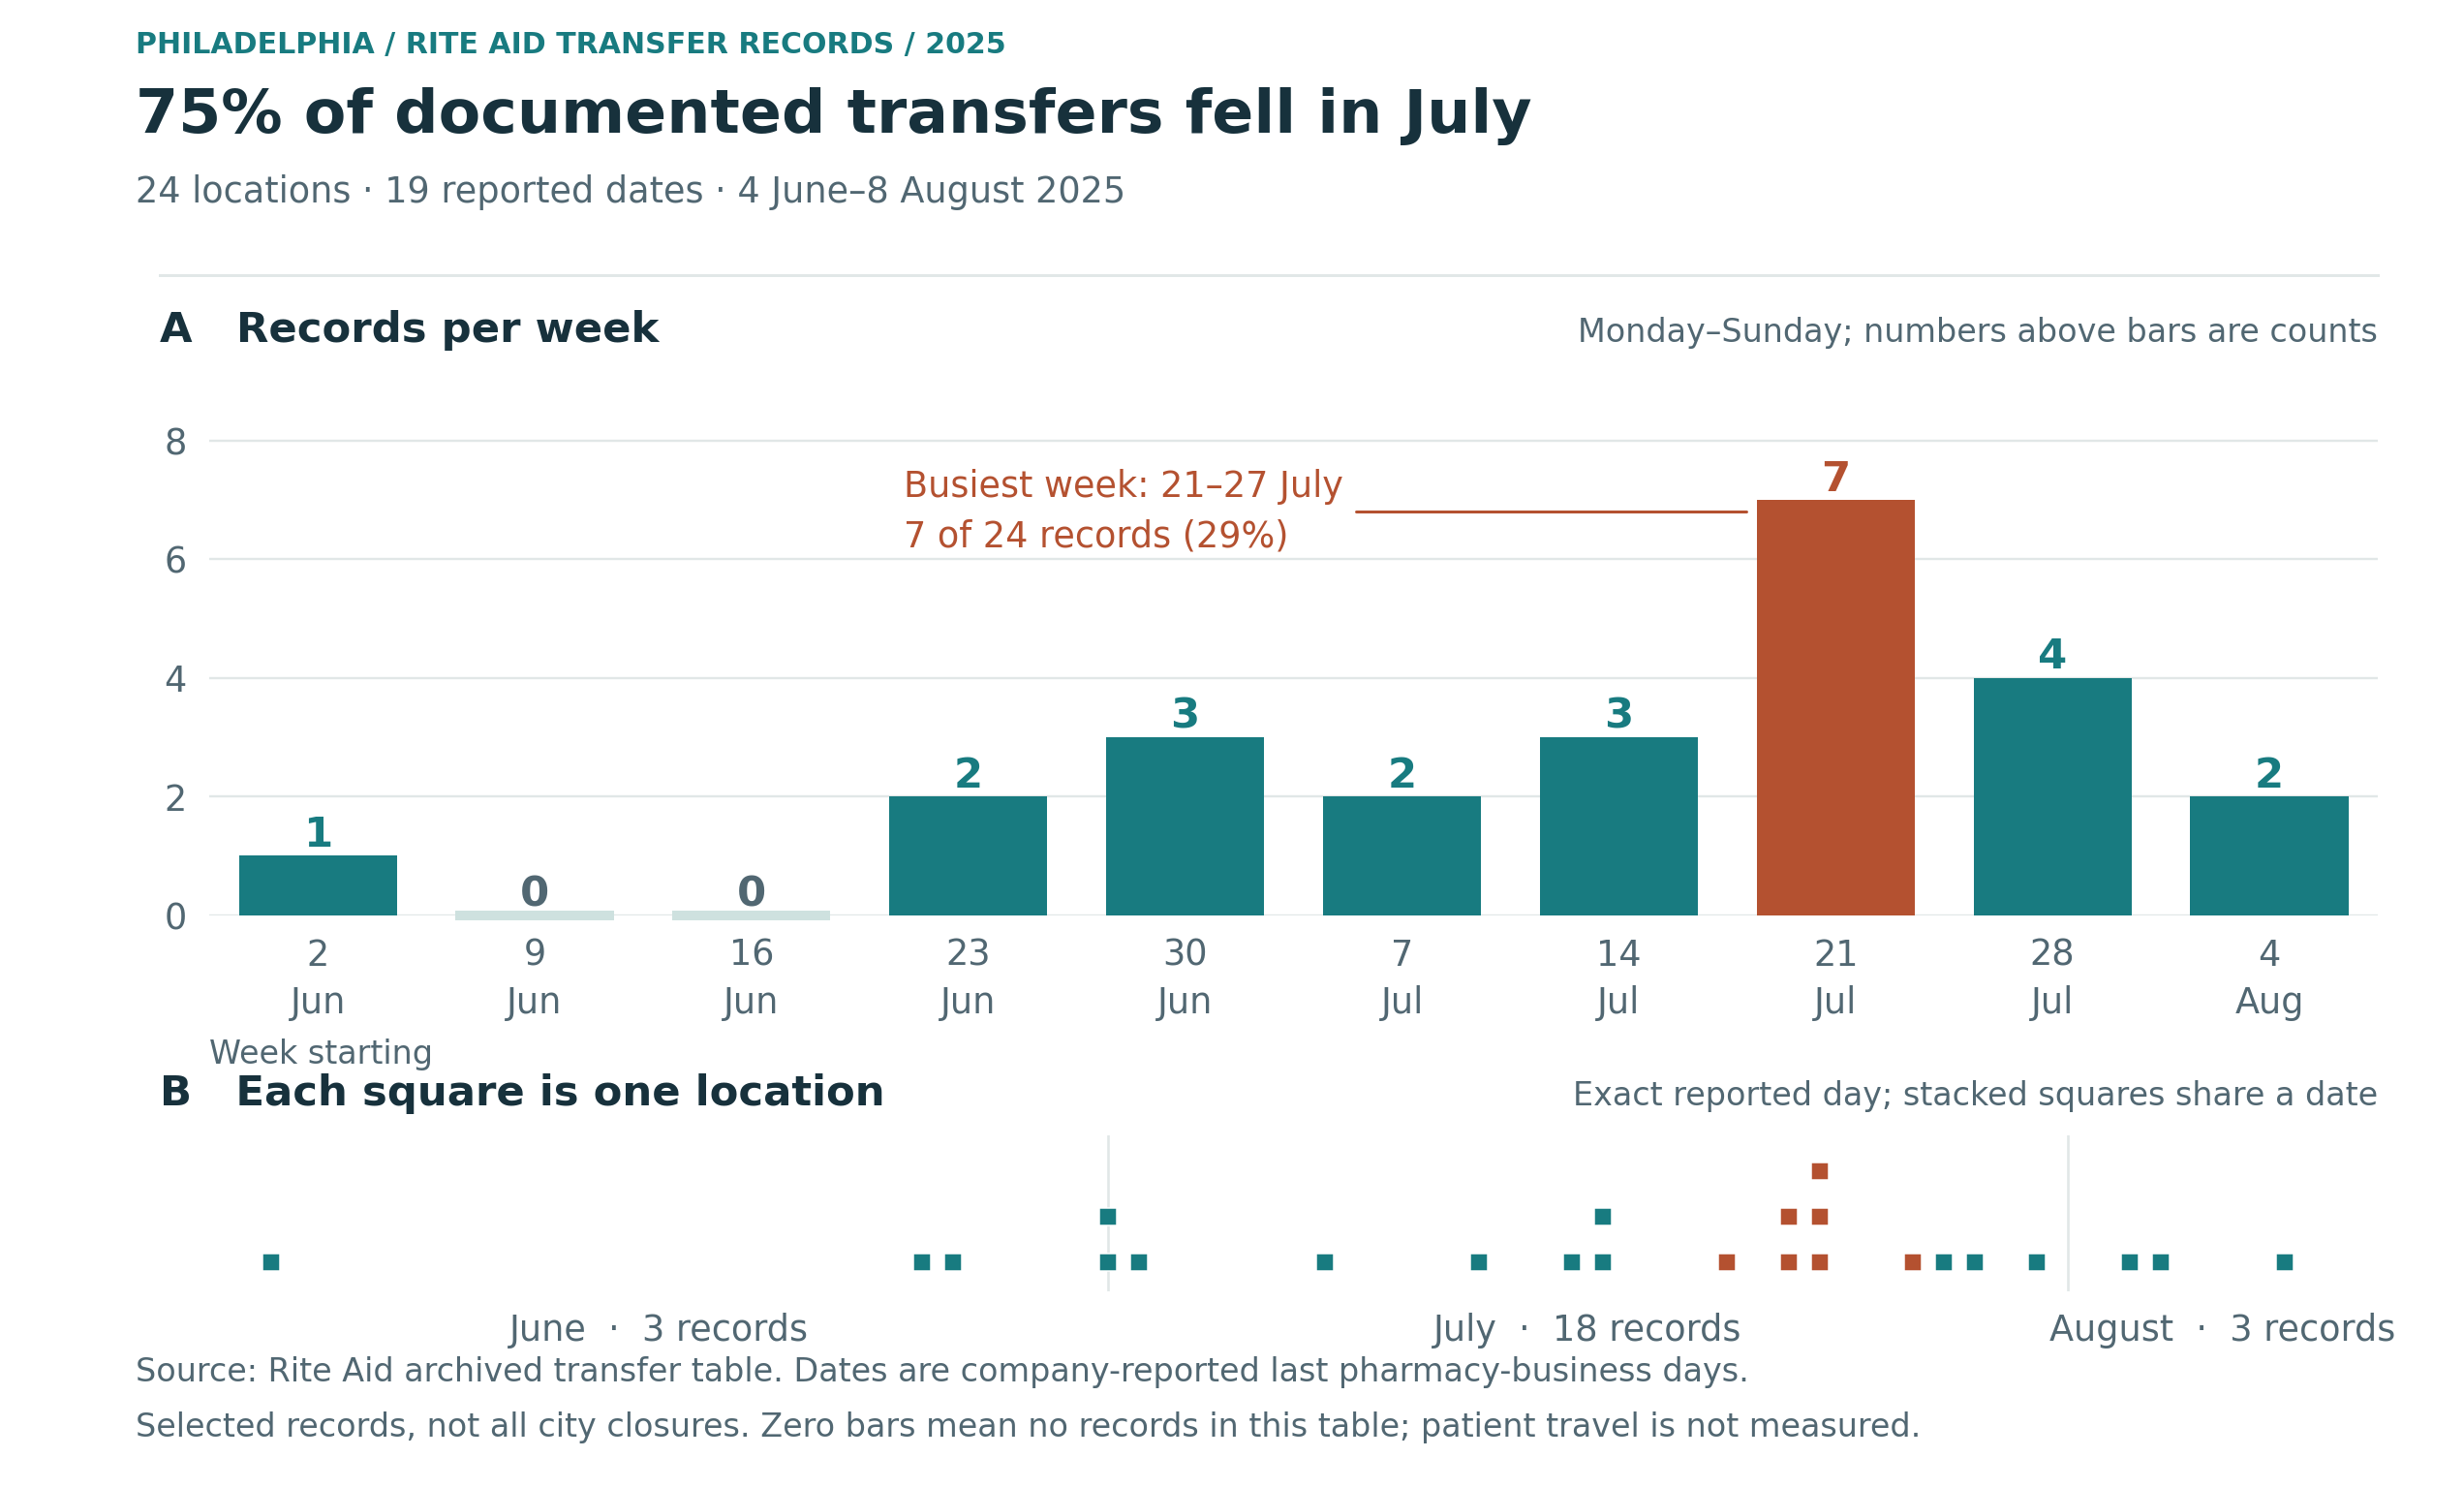

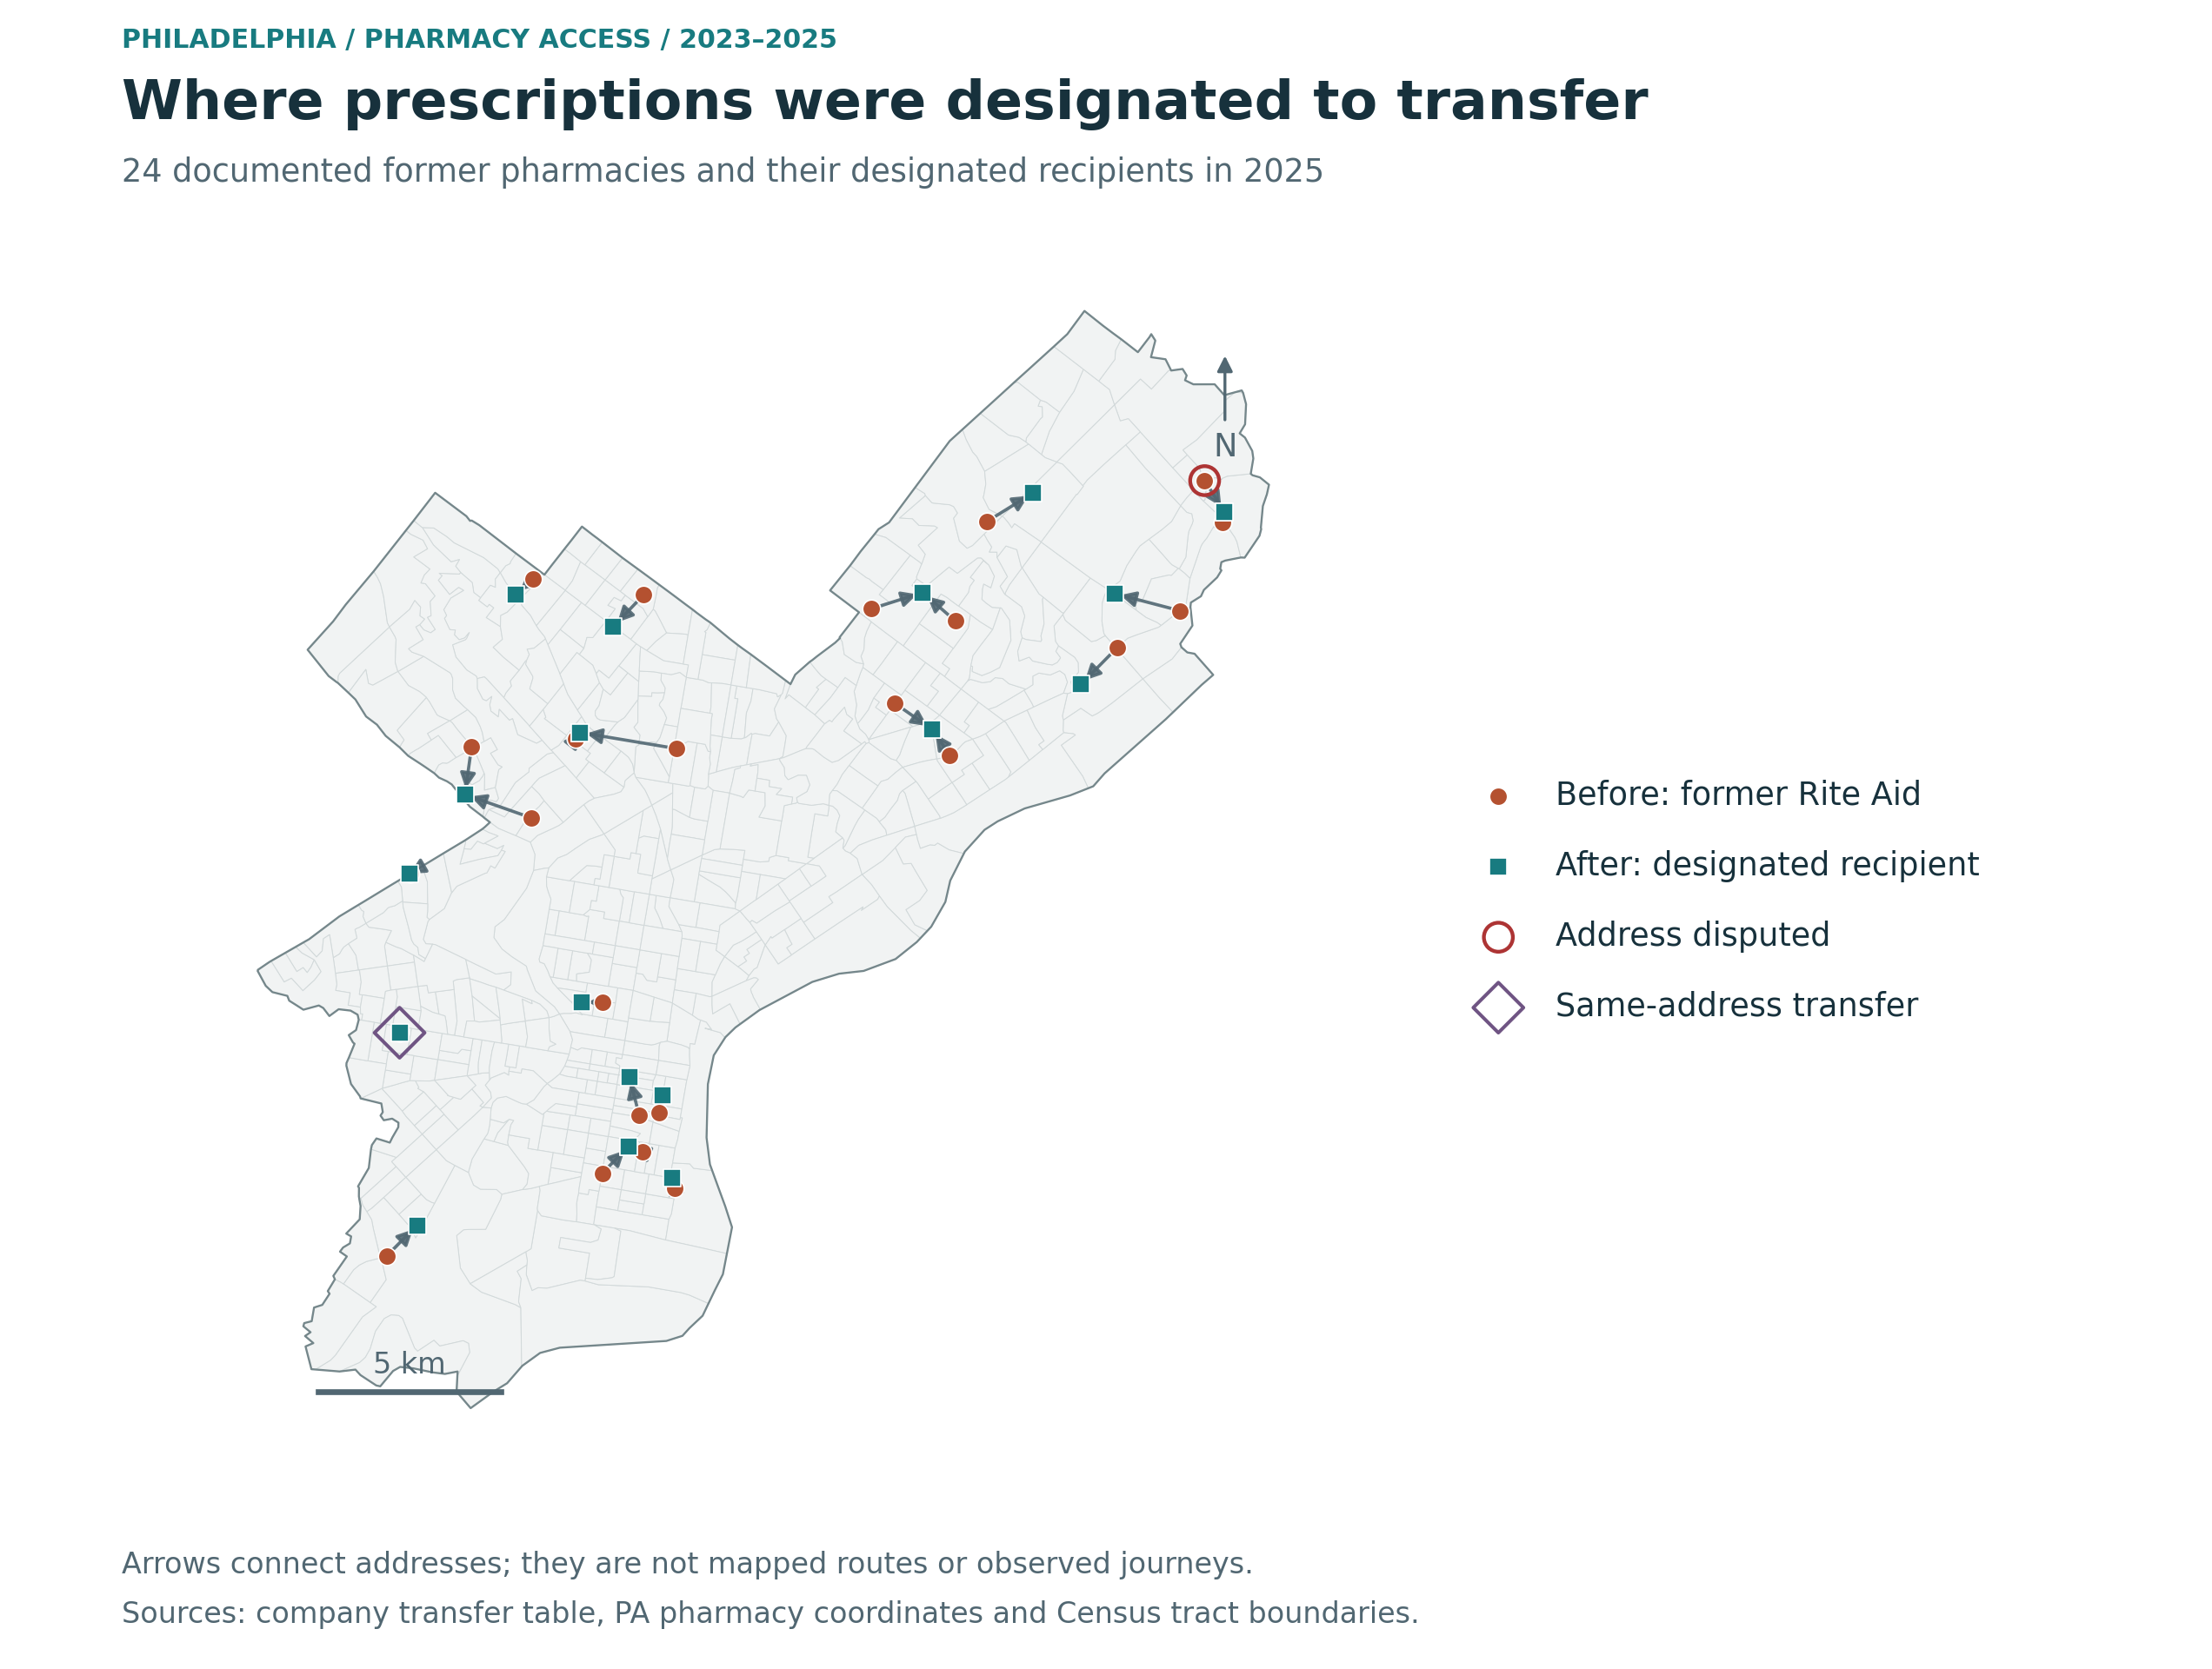

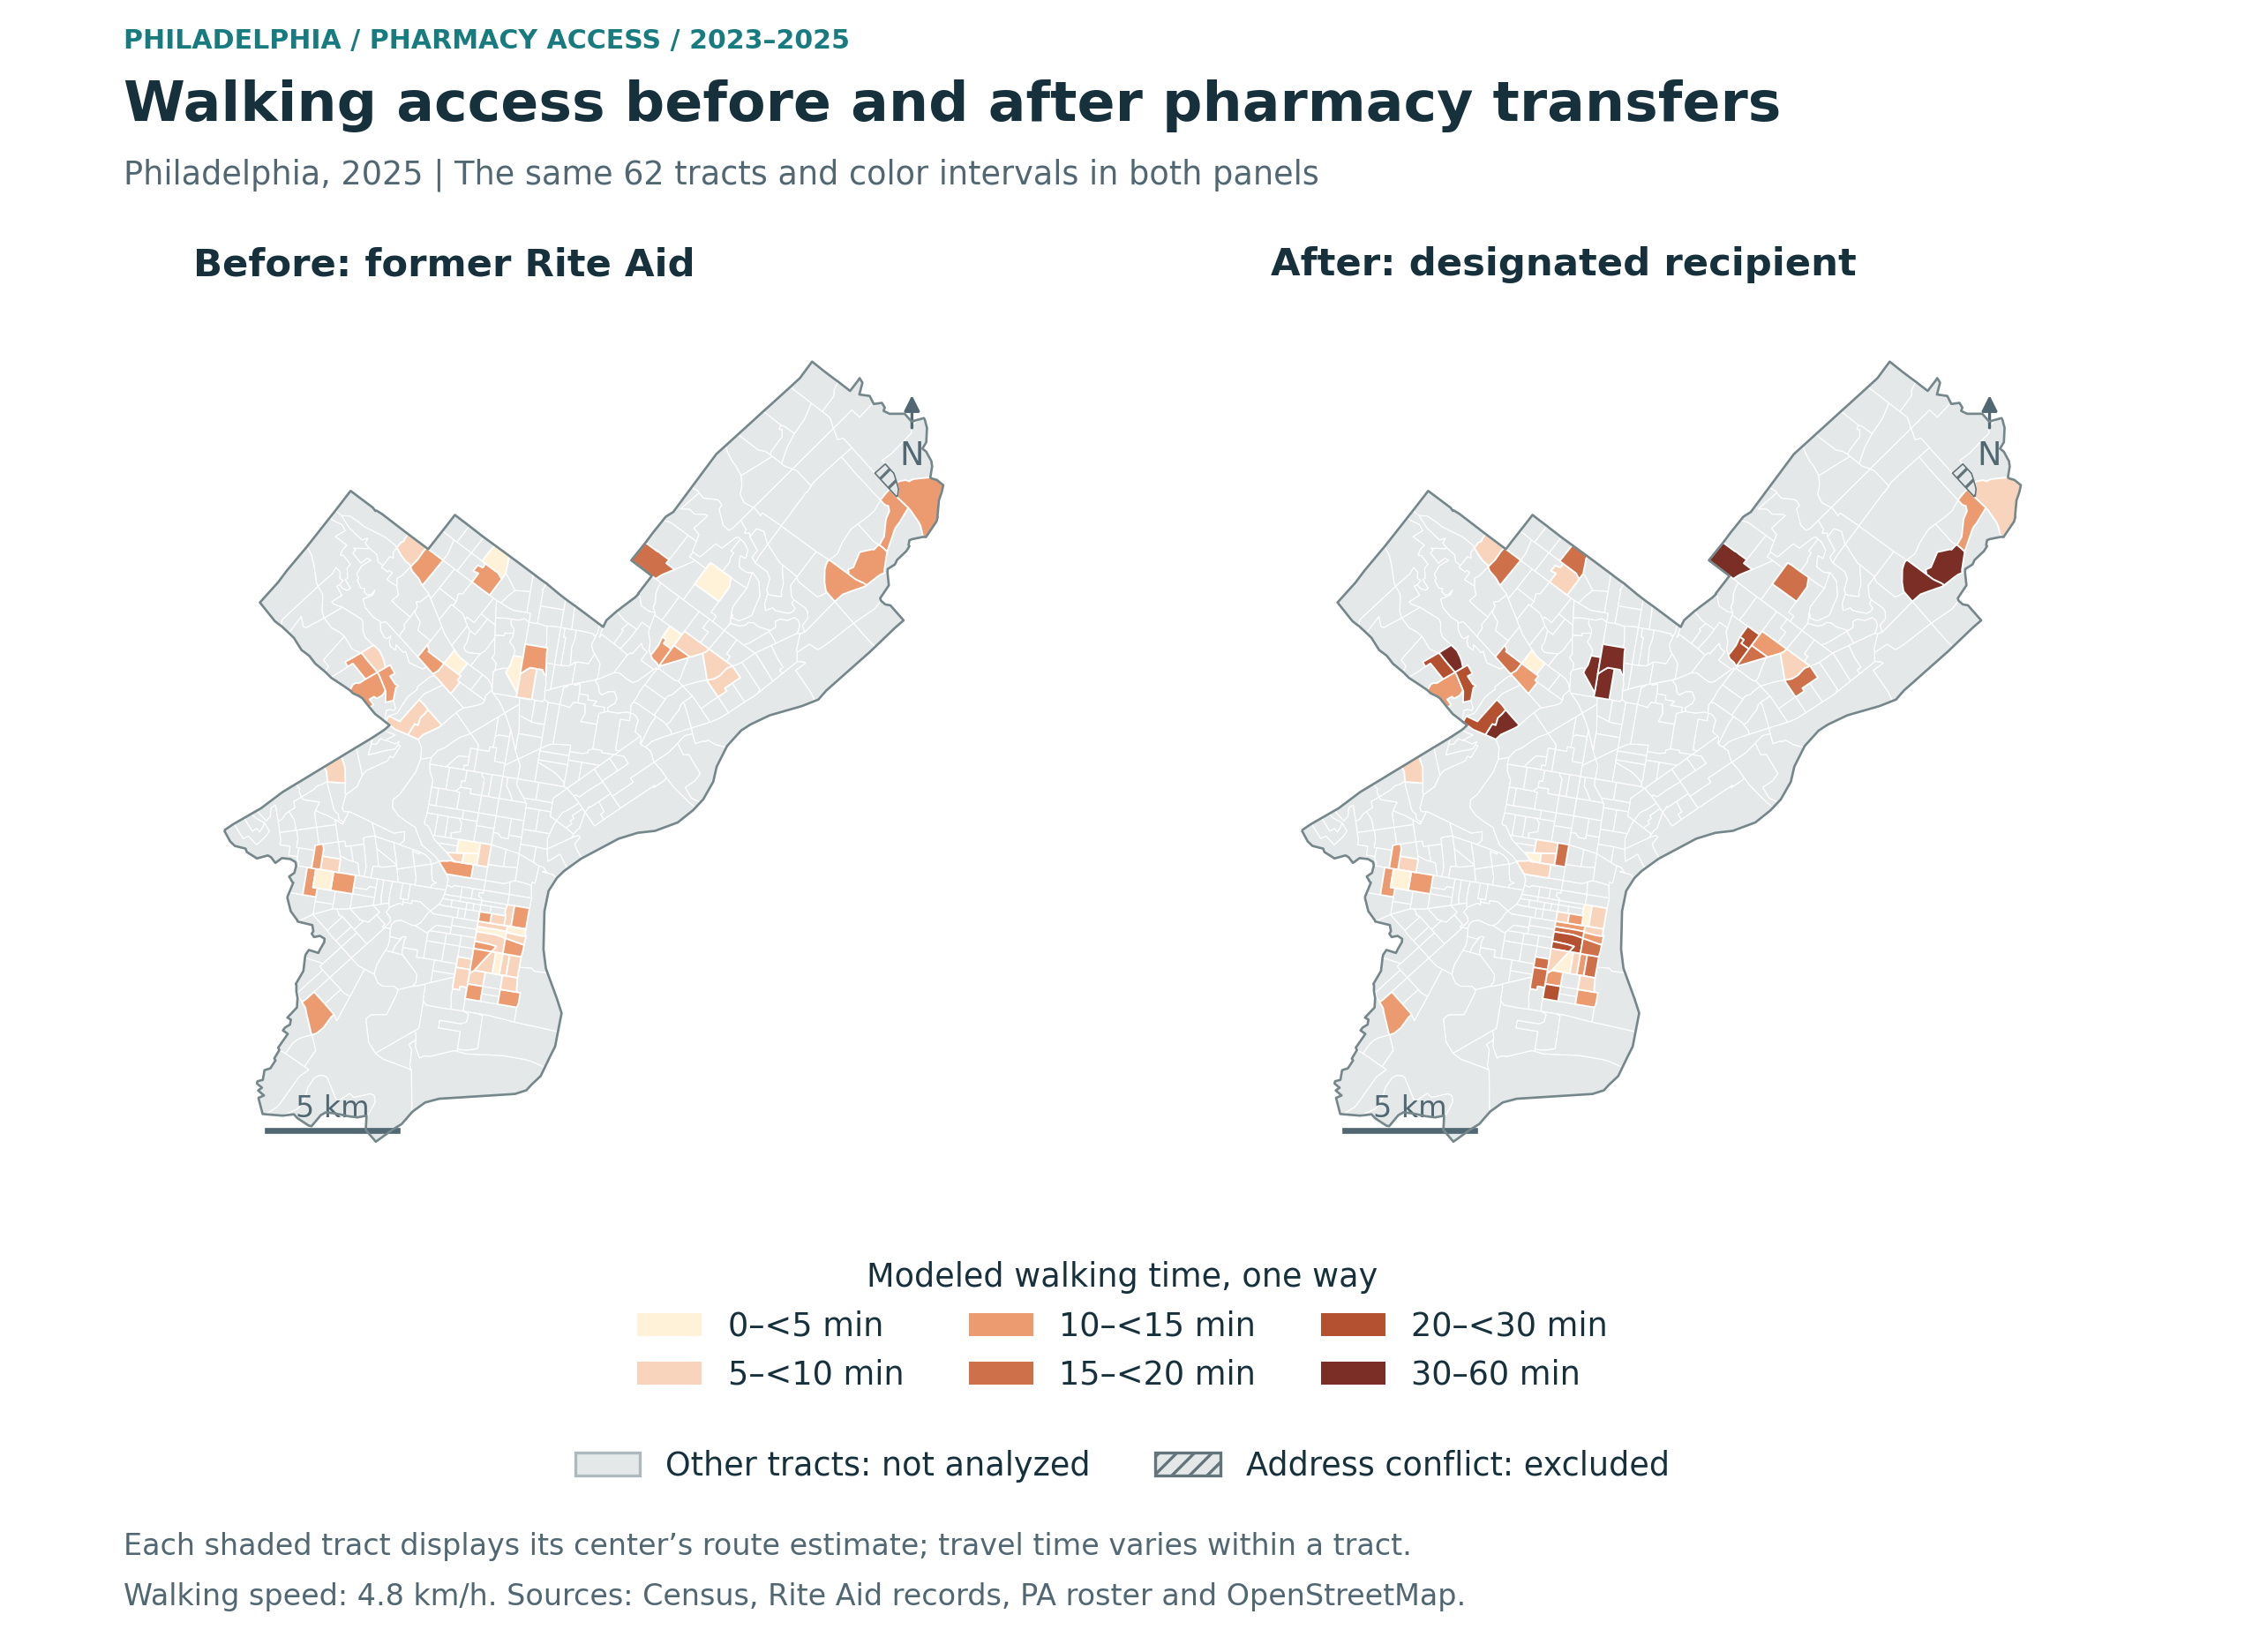

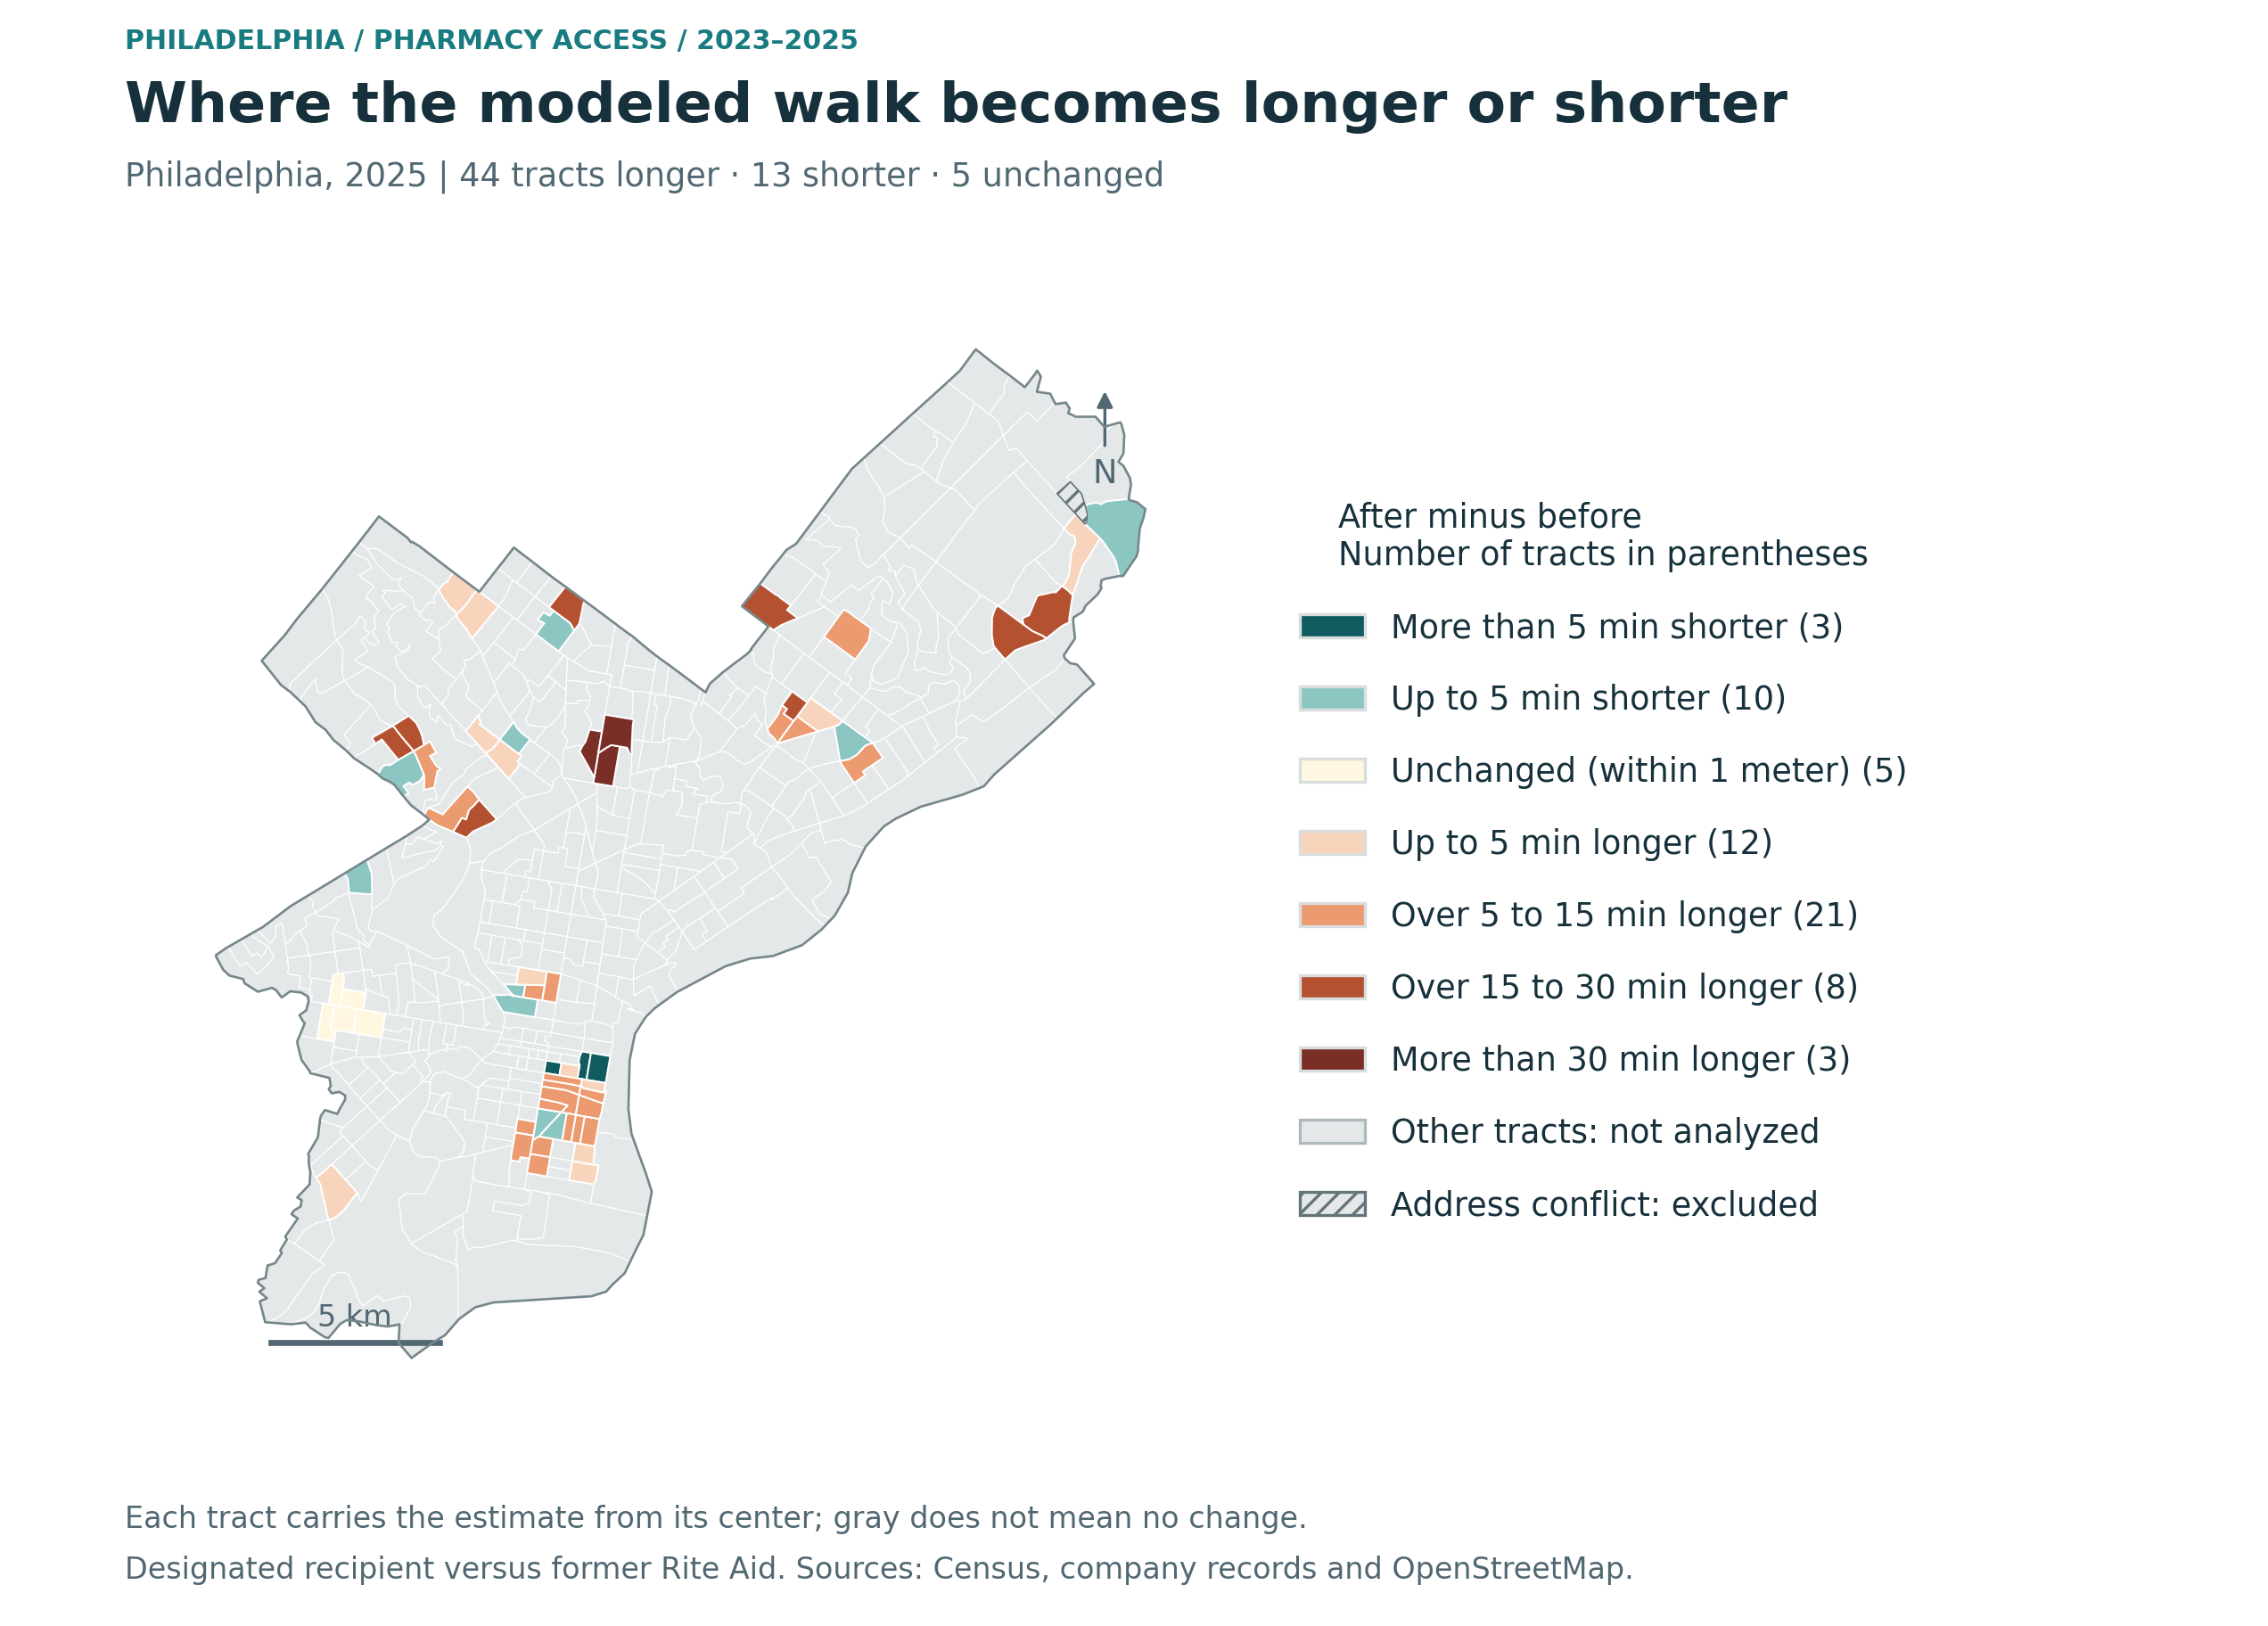

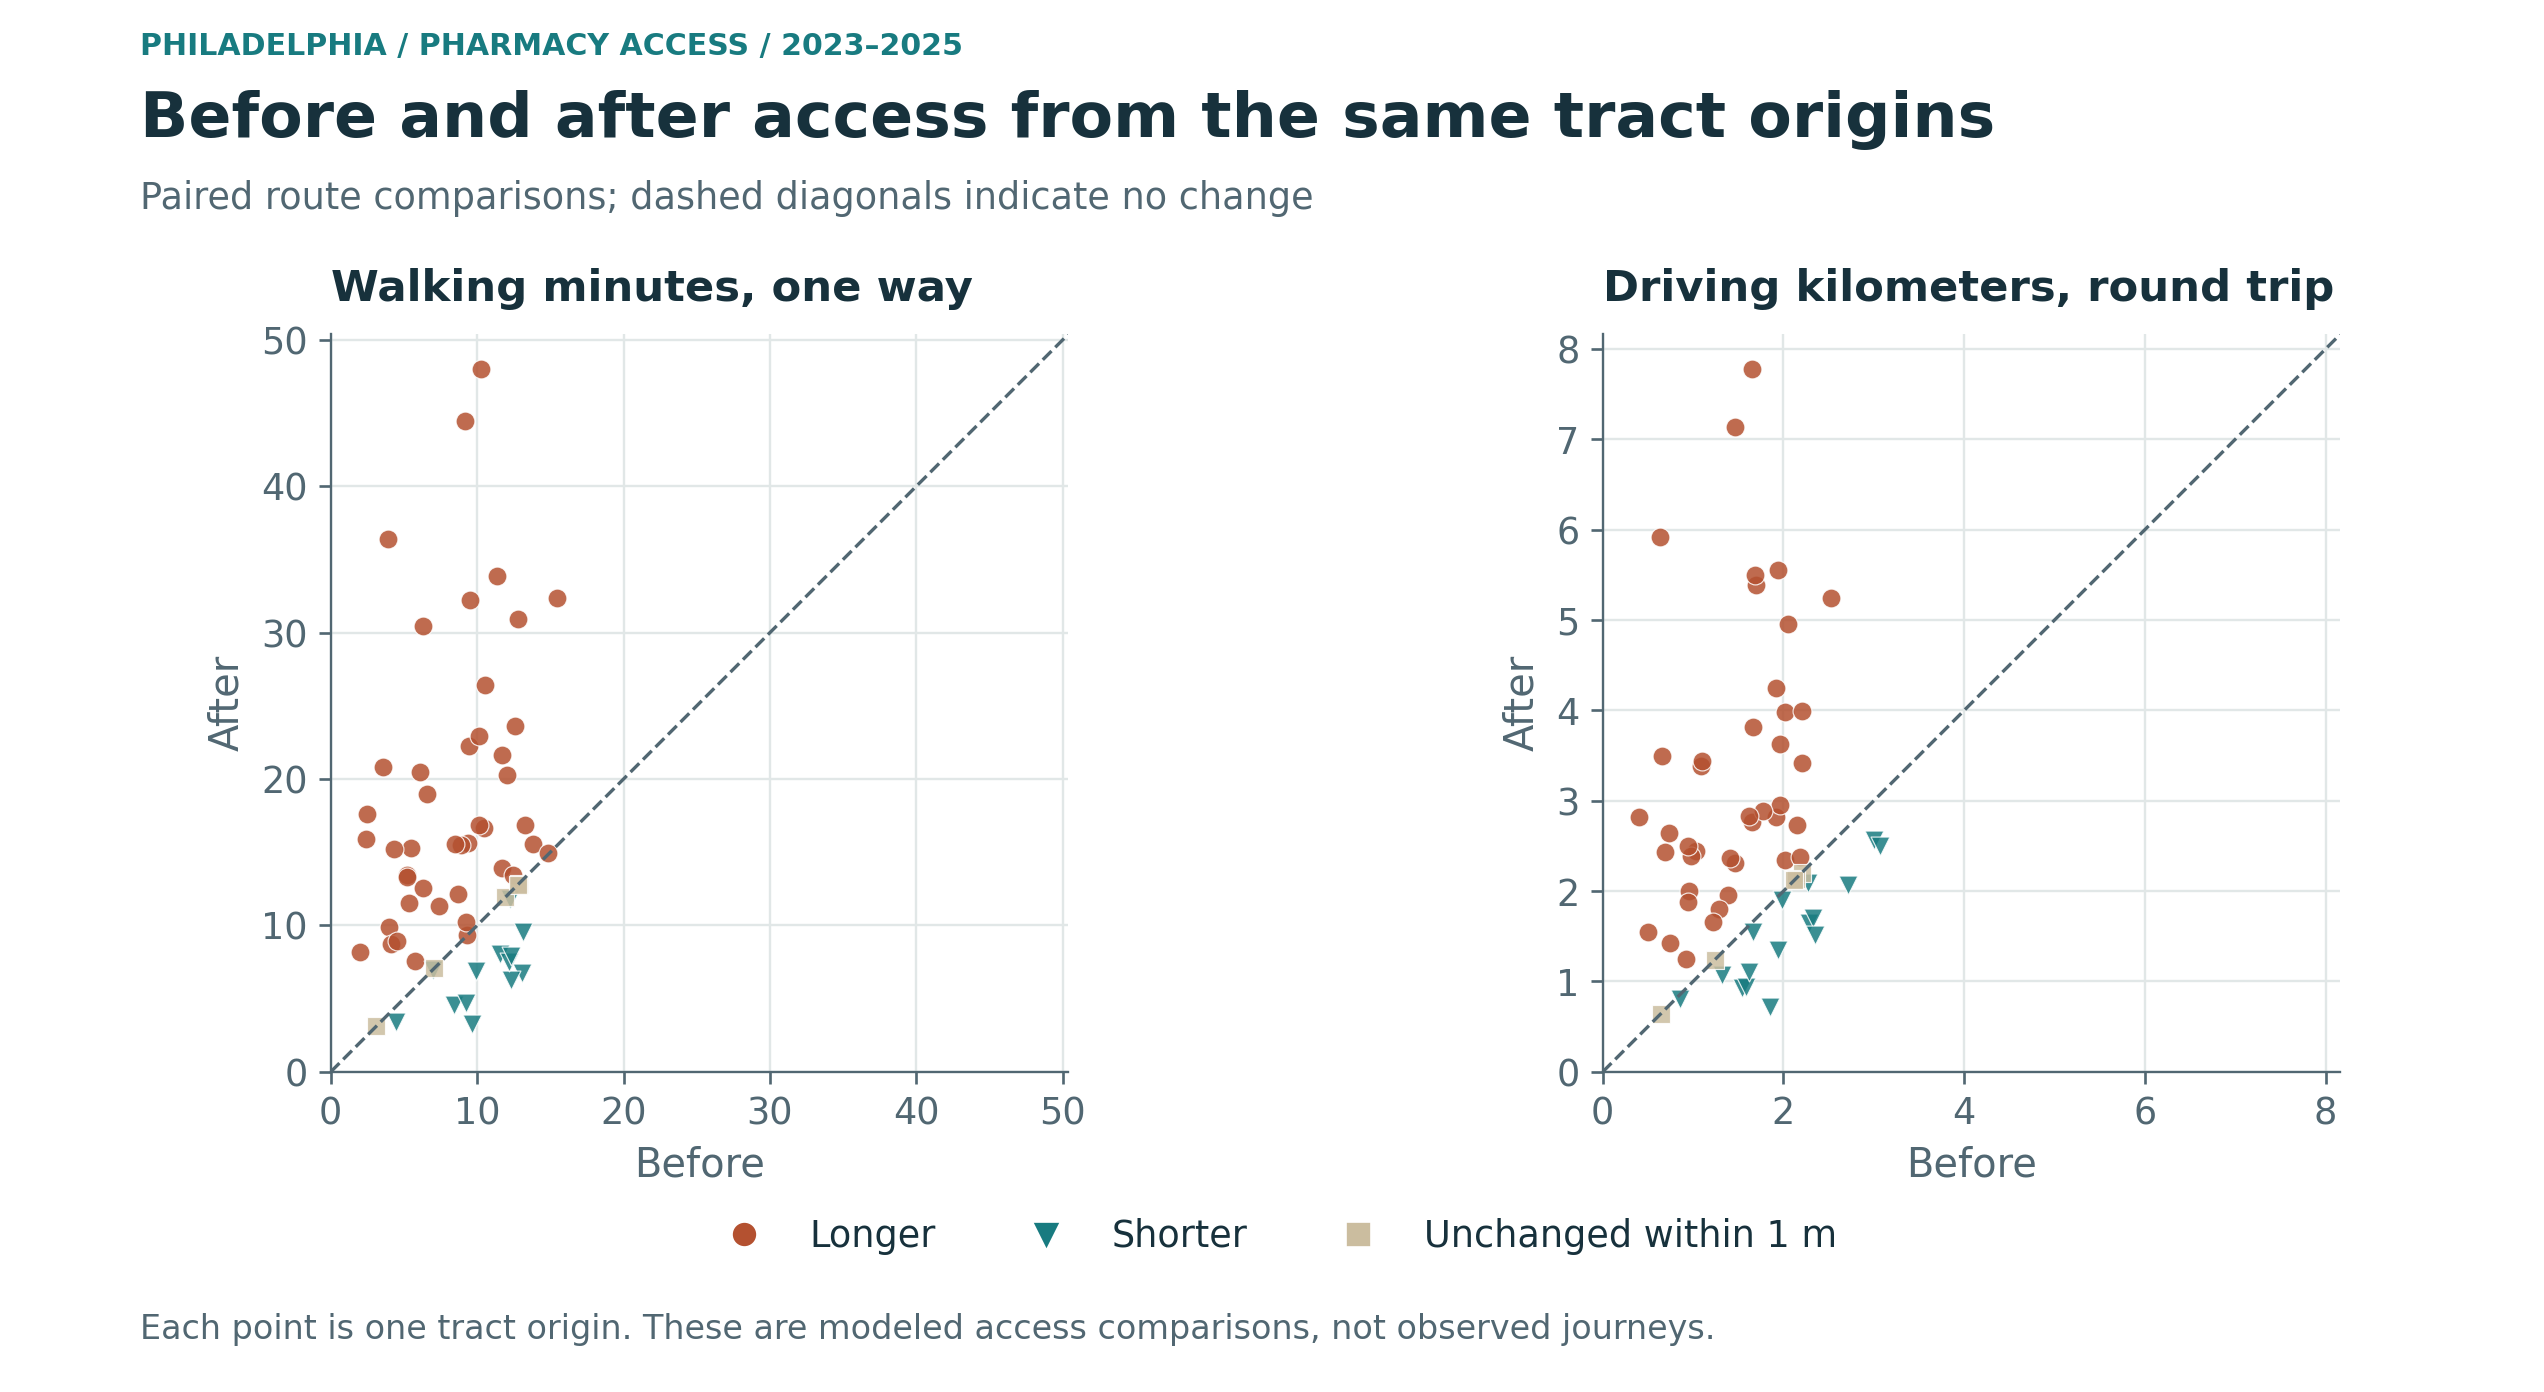

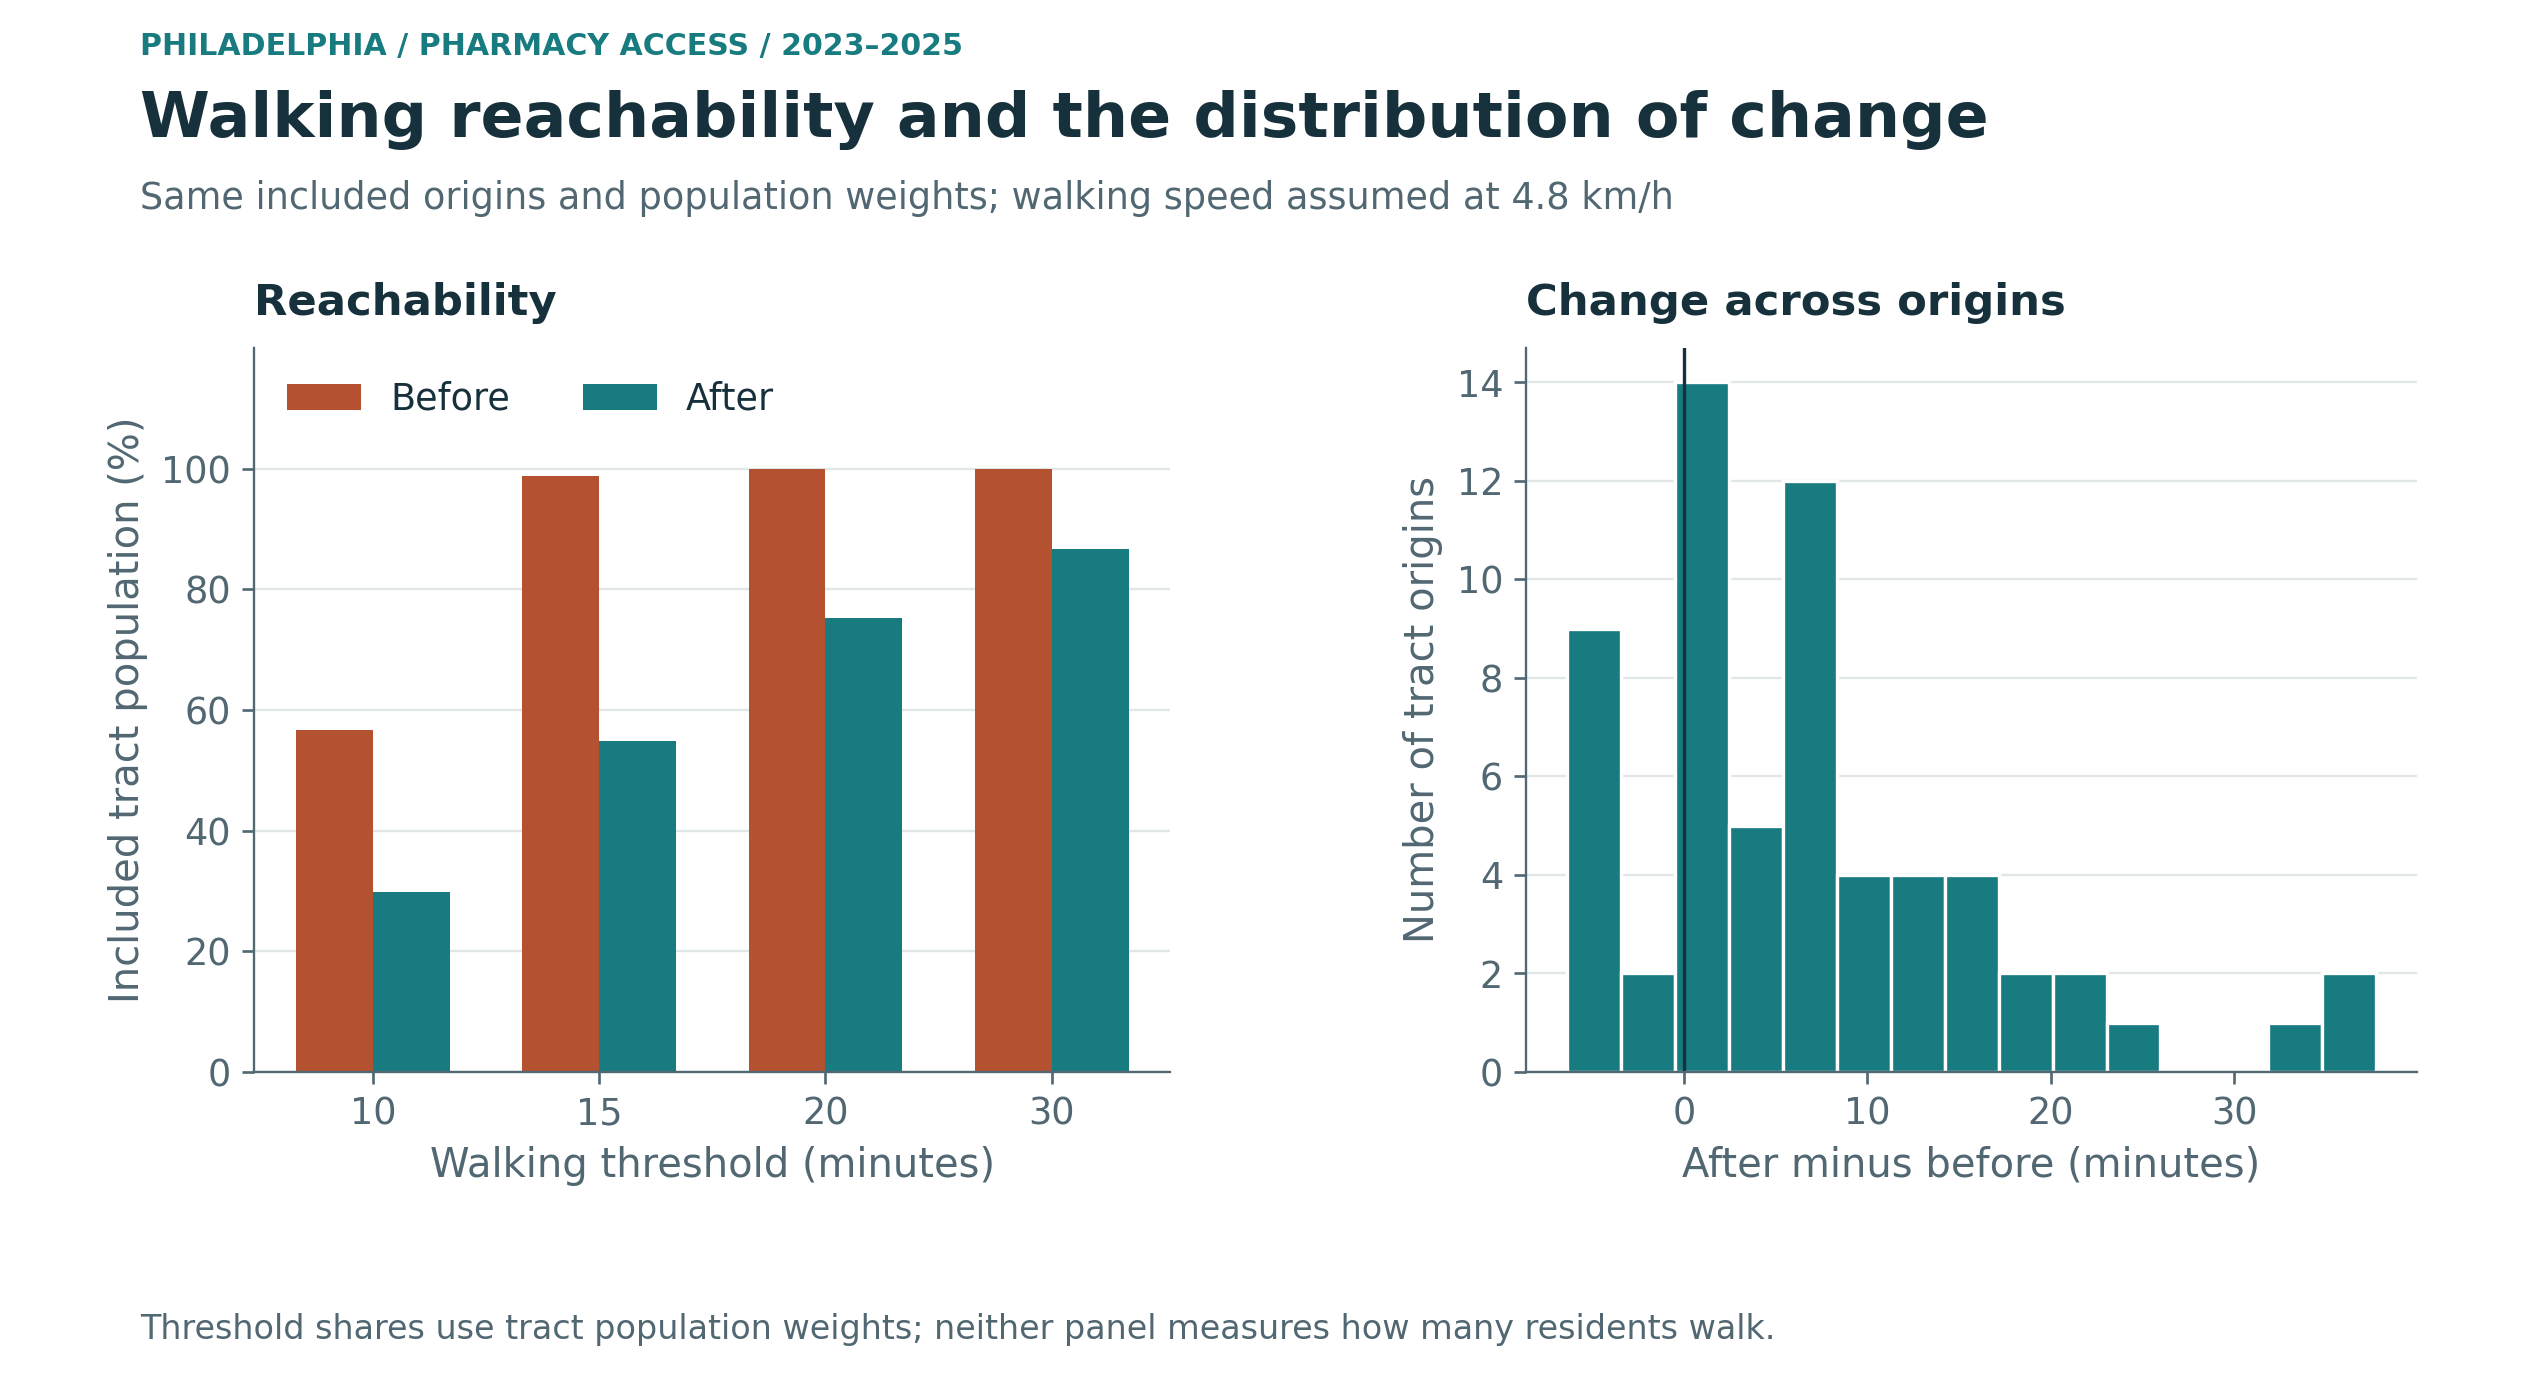

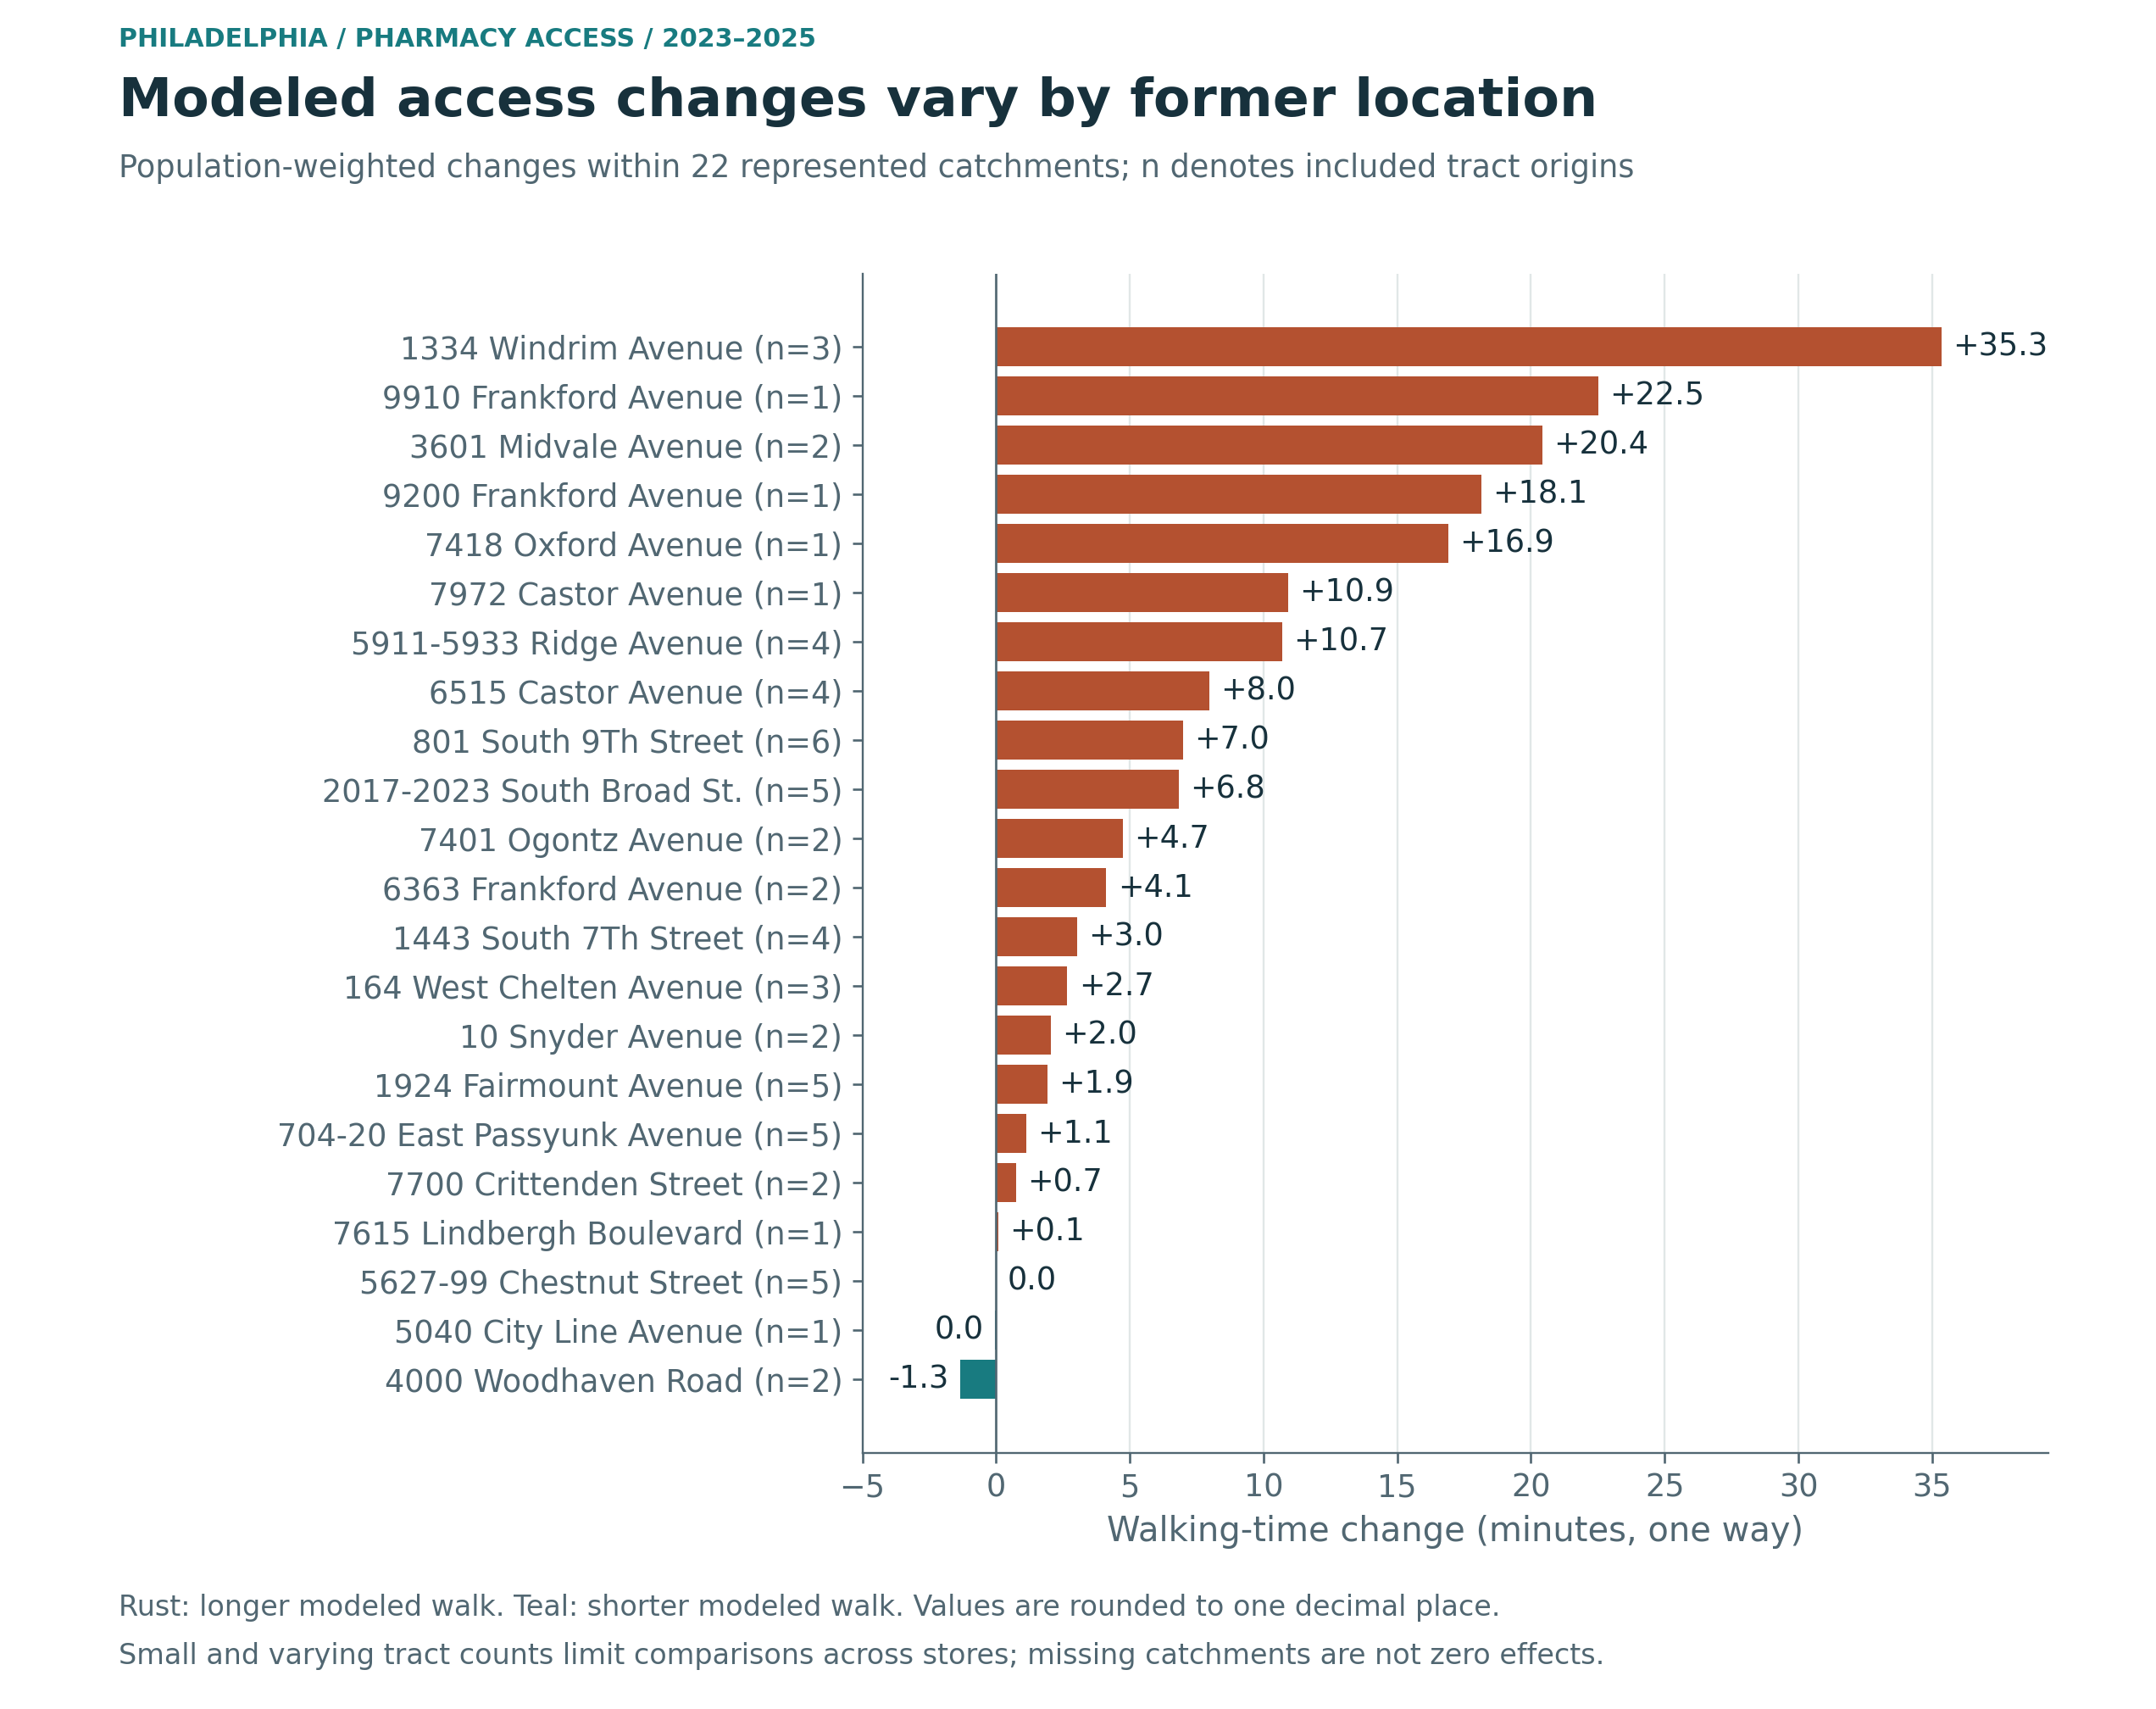

In [6]:
comparison = pd.DataFrame({
    'measure': ['One-way walking minutes', 'Driving round-trip km'],
    'before': [summary['weighted_walk_before_minutes'], summary['weighted_drive_before_roundtrip_km']],
    'after': [summary['weighted_walk_after_minutes'], summary['weighted_drive_after_roundtrip_km']],
    'difference': [summary['weighted_walk_delta_minutes'], summary['weighted_drive_delta_roundtrip_km']]})
display(comparison.round(2))
for file in ['transfer_timeline.png','transfer_destination_map.png','before_after_walking_map.png','walking_change_tract_map.png','before_after_comparison.png','walking_thresholds.png','transfer_by_location.png']:
    display(Image(filename=str(OUT / file)))


The transfer timeline counts records by **Monday–Sunday week**, including weeks with no records in the table. Its second panel retains the exact reported day for each location. **18 of 24 records fall in July (75%)**, and **seven fall in 21–27 July**. These are selected company-reported dates, not a complete citywide closure census. The [website timeline](https://emmanuelsampson-prog.github.io/pharmacy-access-philadelphia/#transfer-timeline) lets readers select a week and inspect its addresses and designated recipients.

In [7]:
from src.timeline import timeline_data
_, weekly, daily, timeline_summary = timeline_data(pairs)
assert weekly.records.sum() == daily.records.sum() == len(pairs)
assert timeline_summary['monthly_records']['2025-07'] == 18
assert timeline_summary['peak_week_records'] == 7
display(weekly)
print('Three quarters of the documented transfers have reported dates in July.')


,week_start,week_end,records
0,2025-06-02,2025-06-08,1
1,2025-06-09,2025-06-15,0
2,2025-06-16,2025-06-22,0
3,2025-06-23,2025-06-29,2
4,2025-06-30,2025-07-06,3
5,2025-07-07,2025-07-13,2
6,2025-07-14,2025-07-20,3
7,2025-07-21,2025-07-27,7
8,2025-07-28,2025-08-03,4
9,2025-08-04,2025-08-10,2


Three quarters of the documented transfers have reported dates in July.


The access maps shade the 62 eligible census tracts using the result calculated at each tract center. Before and after use identical color intervals. The change map separates longer, shorter and unchanged access; gray means no primary estimate, not zero change. Tract-wide shading does not imply that all residents have the same journey. Hatching identifies the excluded address conflict.

## 5. Neighborhood comparisons and spatial sensitivity
Poverty and household vehicle availability come from fixed 2018–2022 ACS estimates. The comparisons describe included origins and do not identify individual effects. Threshold sensitivities change the composition of the catchment sample; they are not confidence intervals.

,group,tracts,weighted_walk_delta_minutes,weighted_drive_delta_roundtrip_km
0,Poverty below 20%,43,6.18,1.01
1,Poverty at least 20%,19,8.62,1.38
2,No vehicle below 30%,41,7.23,1.15
3,No vehicle at least 30%,21,6.73,1.12


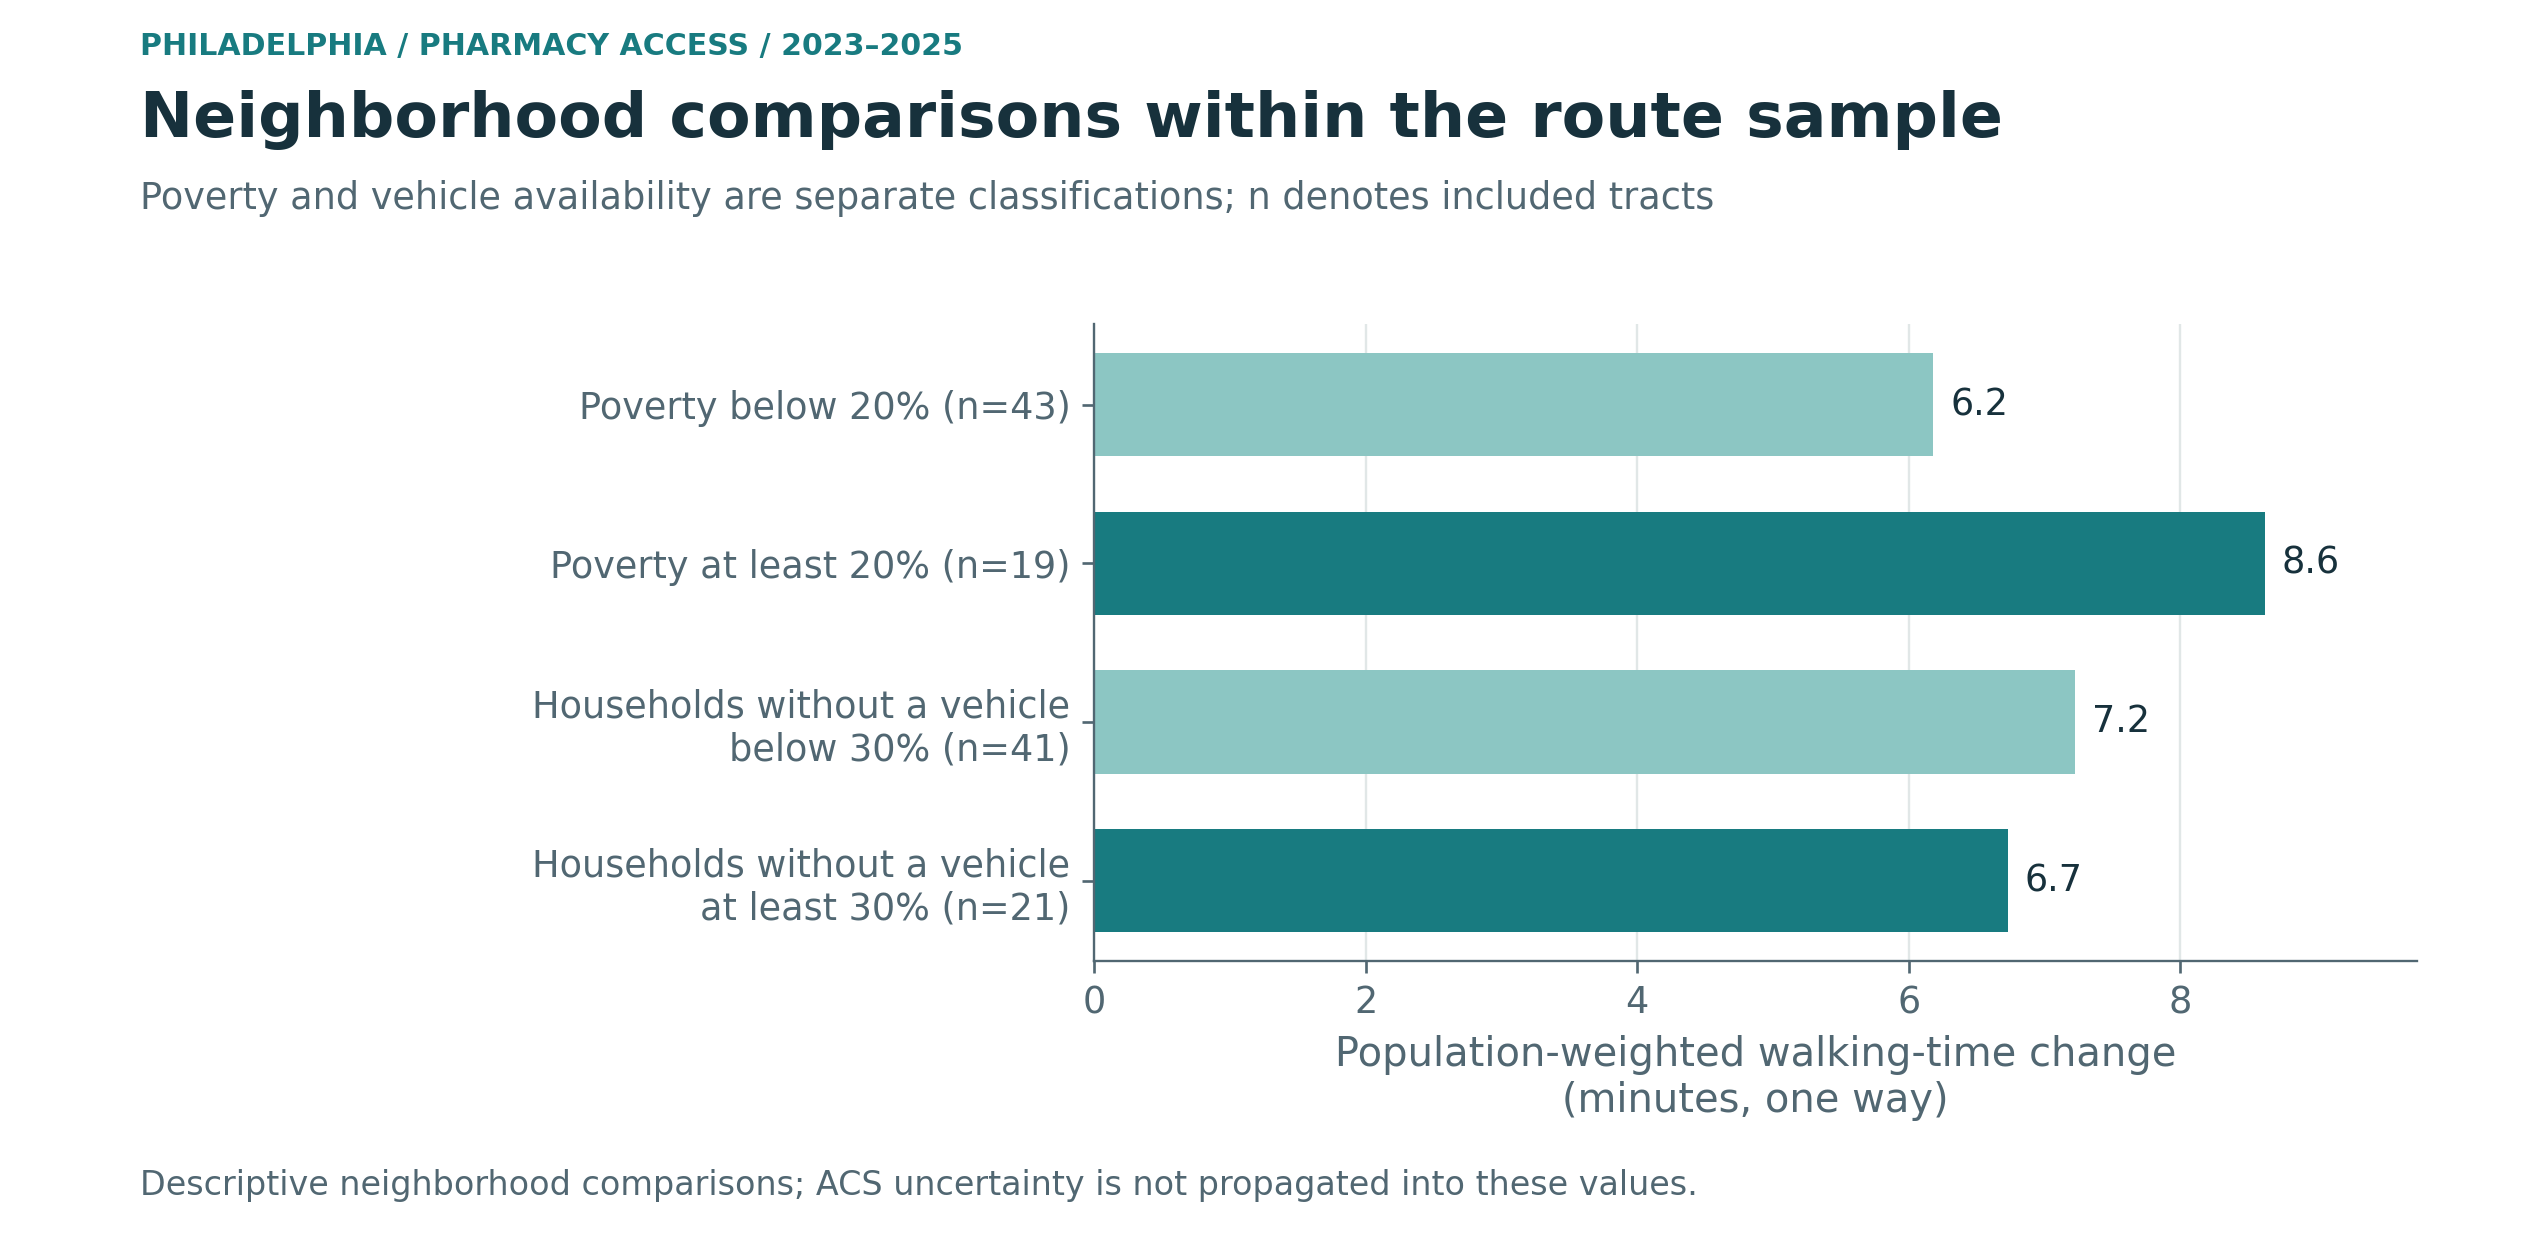

,radius_m,max_snap_m,tracts,weighted_walk_delta_minutes,weighted_drive_delta_roundtrip_km
0,500,100,29,9.36,1.51
1,500,200,29,9.36,1.51
2,500,300,29,9.36,1.51
3,800,100,61,6.89,1.12
4,800,200,62,7.06,1.14
5,800,300,62,7.06,1.14
6,1000,100,94,6.79,1.07
7,1000,200,96,6.85,1.09
8,1000,300,96,6.85,1.09


Including the disputed Academy Road address:


tracts                                     63.000000
population_context                     266821.000000
represented_transfer_pairs                 23.000000
weighted_walk_before_km                     0.715631
median_walk_before_km                       0.744611
weighted_walk_after_km                      1.287408
median_walk_after_km                        1.077188
weighted_walk_delta_km                      0.571777
median_walk_delta_km                        0.495020
weighted_walk_before_minutes                8.945391
median_walk_before_minutes                  9.307636
weighted_walk_after_minutes                16.092602
median_walk_after_minutes                  13.464851
weighted_walk_delta_minutes                 7.147211
median_walk_delta_minutes                   6.187746
weighted_drive_before_roundtrip_km          1.605874
median_drive_before_roundtrip_km            1.656541
weighted_drive_after_roundtrip_km           2.772249
median_drive_after_roundtrip_km             2.

In [8]:
display(pd.read_csv(OUT / 'before_after_equity.csv')[['group','tracts','weighted_walk_delta_minutes','weighted_drive_delta_roundtrip_km']].round(2))
display(Image(filename=str(OUT / 'before_after_equity.png')))
sensitivity = pd.read_csv(OUT / 'before_after_sensitivity.csv')
display(sensitivity[['radius_m','max_snap_m','tracts','weighted_walk_delta_minutes','weighted_drive_delta_roundtrip_km']].round(2))
print('Including the disputed Academy Road address:')
display(pd.Series(summary['including_disputed_address']))


## 6. Conditional emissions
Use the paired **round-trip driving distance** difference with the EPA approximation of 400 g CO₂ per gasoline-vehicle mile. Do not add another factor of two or a detour multiplier. The hypothetical trip distribution follows the population weights; actual mode shares, trip chaining and trip counts are unknown.

The calculation holds car share fixed between before and after. It cannot measure a walking-to-driving transition or net citywide emissions.

Conditional default: 142.19 kg CO₂ per 1,000 hypothetical person round trips.


,car_share,additional_travel_share,hypothetical_person_roundtrips,tailpipe_co2_delta_kg
0,0.25,0.5,1000,35.55
1,0.25,1.0,1000,71.10
2,0.50,0.5,1000,71.10
3,0.50,1.0,1000,142.19
4,0.75,0.5,1000,106.64
5,0.75,1.0,1000,213.29
6,1.00,0.5,1000,142.19
7,1.00,1.0,1000,284.38


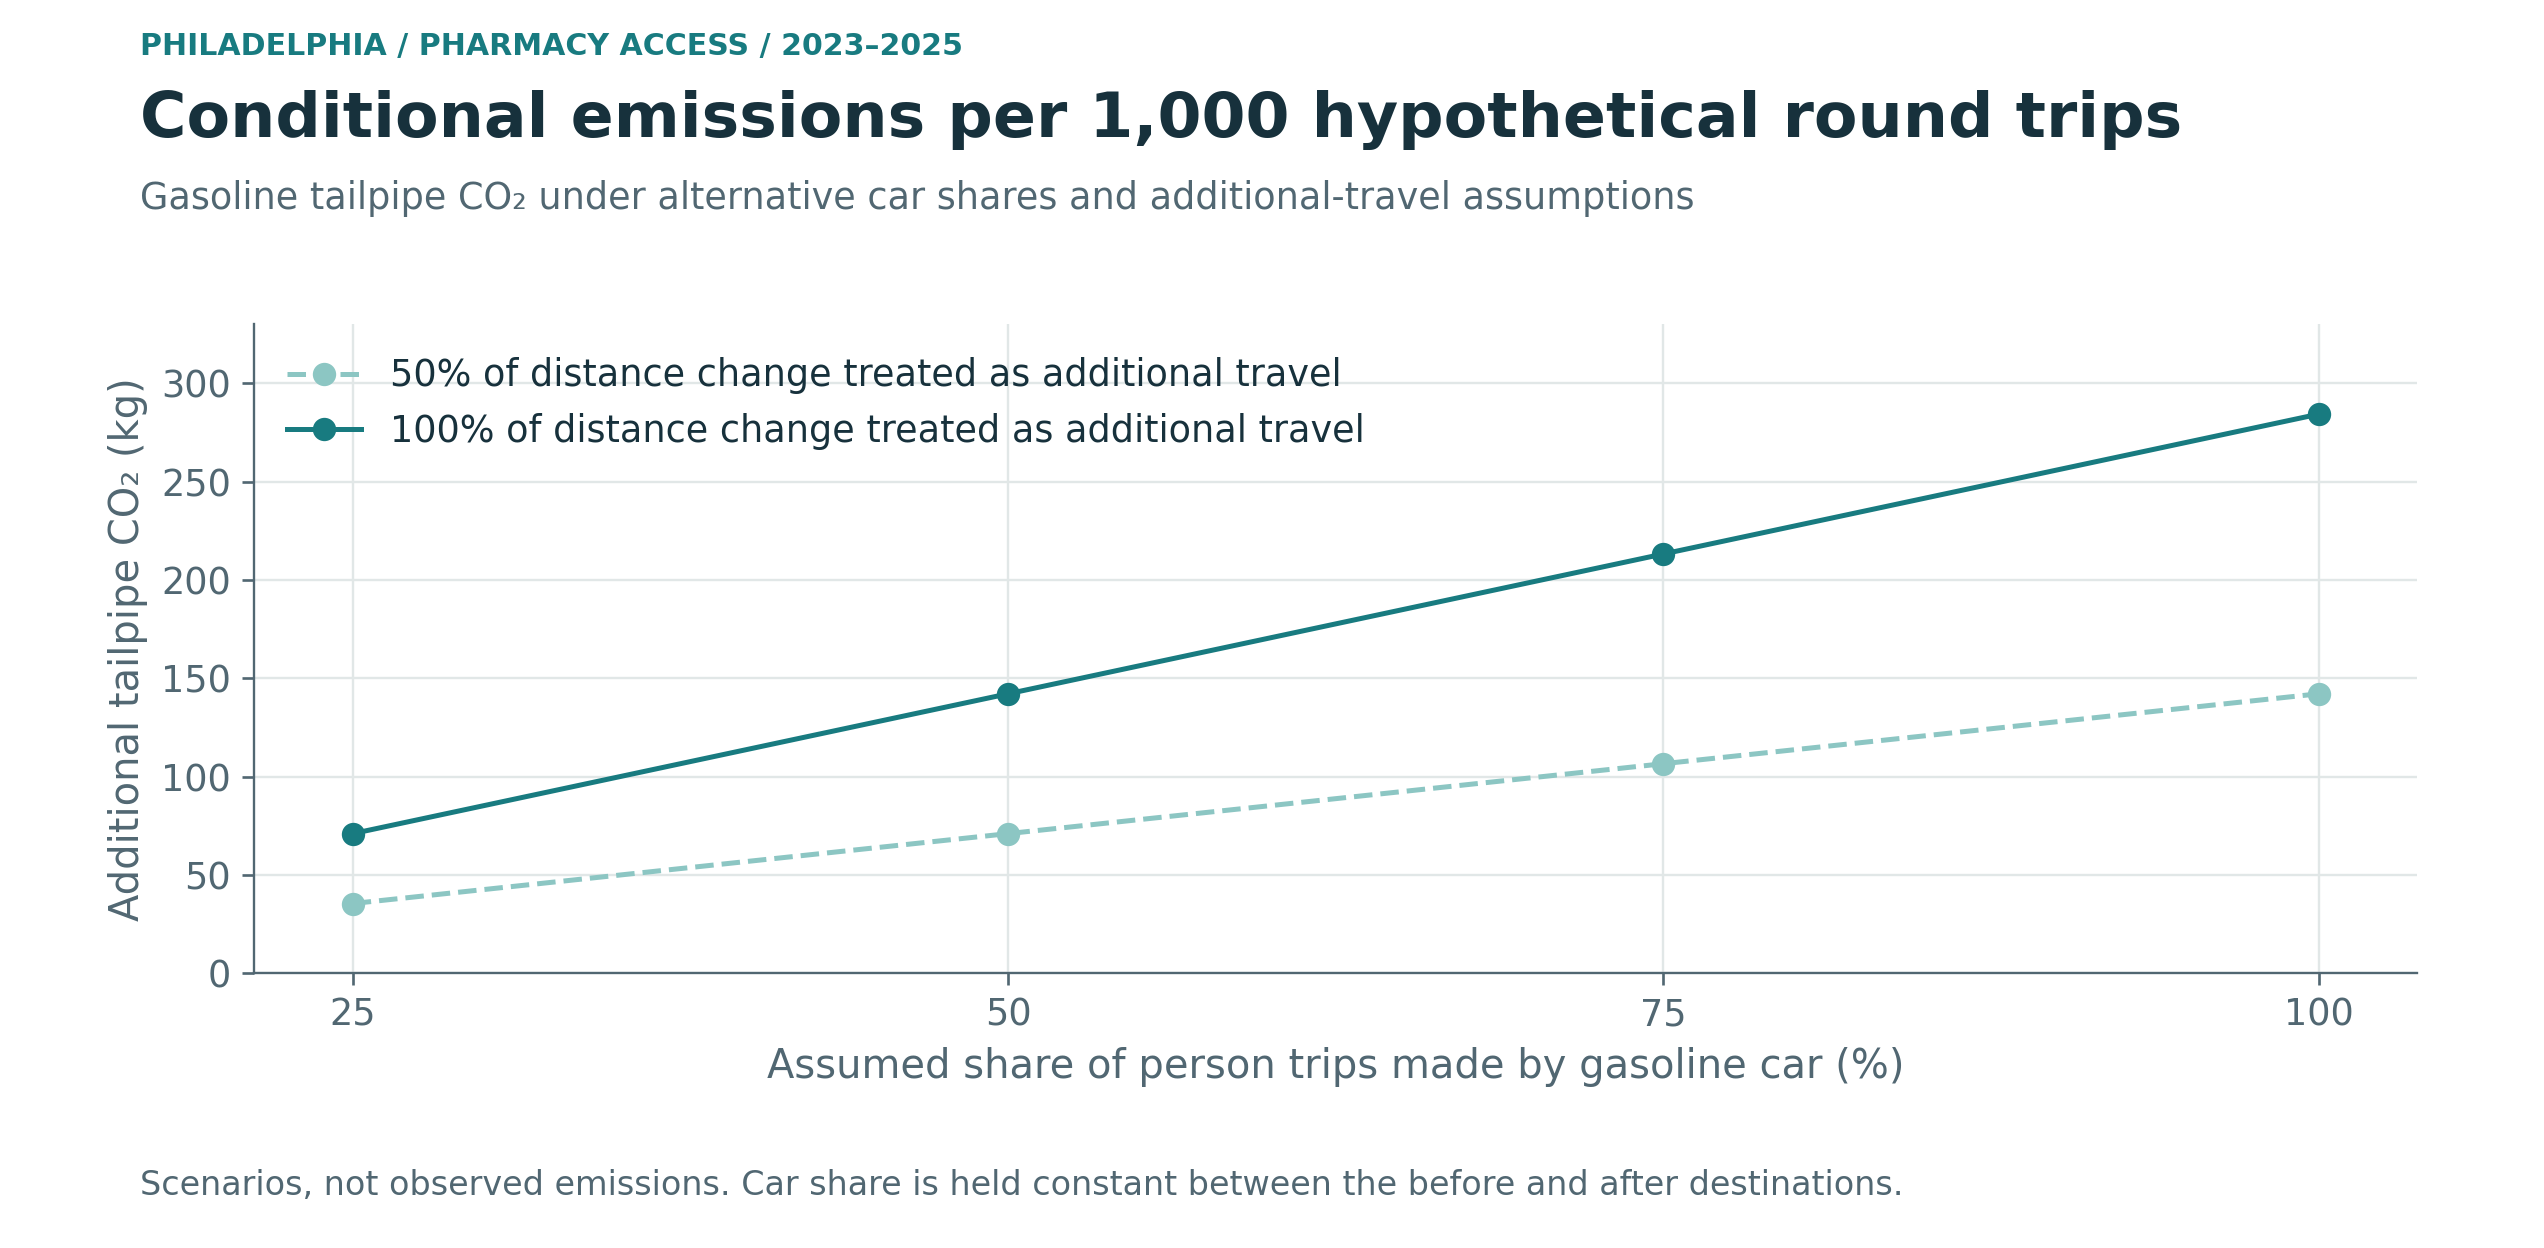

In [9]:
from src.transfer_access import conditional_co2_kg
value = conditional_co2_kg(summary['weighted_drive_delta_roundtrip_km'], trips=1000, car_share=.5)
print(f'Conditional default: {value:.2f} kg CO₂ per 1,000 hypothetical person round trips.')
display(pd.read_csv(OUT / 'before_after_emissions.csv').round(2))
display(Image(filename=str(OUT / 'before_after_emissions.png')))


## 7. Causal interpretation and unfinished outcomes
The proposed primary design is staggered difference-in-differences with direct closure exposure and separately defined spatial spillovers. Observed pretrends, panel stability, clean controls and overlapping events require evaluation. The [mobility notebook](02_mobility_event_study.ipynb) remains input-gated.

A geographic RDD would need a real discontinuity in treatment assignment at a boundary; no such rule has been identified here. A spatial IV would need a relevant, plausibly exogenous instrument satisfying exclusion; none has been established. Neither technique is presented as an estimated result.

The [academic report](../docs/study_report.md) provides the full interpretation, recommendations and limitations. [Data access](../docs/data_access.md) specifies the Penn/Dewey mobility export needed next. The proposed panel is January 2022–December 2025, with 2022 as baseline for 2023–2025 closures. Foot-traffic counts alone cannot identify walking or driving.